Step 1: Dataset Collection & Understanding

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_DIR = "/content/drive/MyDrive/Phishing Detection Project"

In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/Phishing Detection Project"

print(os.path.exists(DATA_DIR))
print(os.listdir(DATA_DIR))

True
['PhiUSIIL_Phishing.csv', 'dataset_full.csv', 'X_train_smote.npy', 'eda_plots', 'models', 'scaler.pkl', 'cross_scaler.pkl', 'y_test.npy', 'y_train.npy', 'X_test.npy', 'y_cross.npy', 'y_train_smote.npy', 'X_cross.npy', 'X_train.npy', 'config.py', 'final_scaler.pkl', 'X_test_selected.npy', 'X_train_selected.npy', 'ablated_scaler.pkl', 'X_train_ablated.npy', 'X_test_ablated.npy']


In [ ]:
import os
os.listdir(DATA_DIR)

['PhiUSIIL_Phishing.csv',
 'dataset_full.csv',
 'X_train_smote.npy',
 'eda_plots',
 'models',
 'scaler.pkl',
 'cross_scaler.pkl',
 'y_test.npy',
 'y_train.npy',
 'X_test.npy',
 'y_cross.npy',
 'y_train_smote.npy',
 'X_cross.npy',
 'X_train.npy',
 'config.py',
 'final_scaler.pkl',
 'X_test_selected.npy',
 'X_train_selected.npy',
 'ablated_scaler.pkl',
 'X_train_ablated.npy',
 'X_test_ablated.npy']

In [ ]:
import pandas as pd

phiusiil = pd.read_csv(f'{DATA_DIR}/PhiUSIIL_Phishing.csv')
vrbancic = pd.read_csv(f'{DATA_DIR}/dataset_full.csv')

print(phiusiil.shape, vrbancic.shape)

(235795, 56) (88647, 112)


In [ ]:
print("PhiUSIIL info")
phiusiil.info()

PhiUSIIL info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  

In [ ]:
print("Vrbancic info")
vrbancic.info()

Vrbancic info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88647 entries, 0 to 88646
Columns: 112 entries, qty_dot_url to phishing
dtypes: float64(1), int64(111)
memory usage: 75.7 MB


In [ ]:
phiusiil.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [ ]:
vrbancic.describe().T

,count,mean,std,min,25%,50%,75%,max
qty_dot_url,88647.0,2.191343,1.235636,1.0,2.0,2.0,2.0,24.0
qty_hyphen_url,88647.0,0.328810,1.119286,0.0,0.0,0.0,0.0,35.0
qty_underline_url,88647.0,0.113879,0.657767,0.0,0.0,0.0,0.0,21.0
qty_slash_url,88647.0,1.281781,1.893929,0.0,0.0,0.0,2.0,44.0
qty_questionmark_url,88647.0,0.009329,0.112568,0.0,0.0,0.0,0.0,9.0
...,...,...,...,...,...,...,...,...
qty_redirects,88647.0,0.343903,0.783892,-1.0,0.0,0.0,1.0,17.0
url_google_index,88647.0,0.001410,0.058640,-1.0,0.0,0.0,0.0,1.0
domain_google_index,88647.0,0.002019,0.063250,-1.0,0.0,0.0,0.0,1.0
url_shortened,88647.0,0.005482,0.073841,0.0,0.0,0.0,0.0,1.0


In [ ]:
for col in ['qty_redirects', 'url_google_index', 'domain_google_index']:
    print(col, (vrbancic[col] == -1).sum())

qty_redirects 6949
url_google_index 90
domain_google_index 88


In [ ]:
print(phiusiil.isnull().sum().sum())
print(vrbancic.isnull().sum().sum())

0
0


In [ ]:
print('PhiUSIIL duplicates:', phiusiil.duplicated().sum())
print('Vrbancic duplicates:', vrbancic.duplicated().sum())

PhiUSIIL duplicates: 0
Vrbancic duplicates: 1438


label column and encoding confirmation

In [ ]:
print(phiusiil['label'].value_counts())
print(vrbancic['phishing'].value_counts())

label
1    134850
0    100945
Name: count, dtype: int64
phishing
0    58000
1    30647
Name: count, dtype: int64


common target column on both with 0 = legitimate, 1 = phishing everywhere

In [ ]:
phiusiil['target'] = phiusiil['label'].map({1: 0, 0: 1})
vrbancic['target'] = vrbancic['phishing']

print(phiusiil['target'].value_counts())
print(vrbancic['target'].value_counts())

target
0    134850
1    100945
Name: count, dtype: int64
target
0    58000
1    30647
Name: count, dtype: int64


PhiUSIIL columns grouped by type

In [ ]:
phiusiil_url_based = [
    'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD',
    'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb',
    'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar',
    'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL',
    'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
    'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS',
]

phiusiil_webpage_based = [
    'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore',
    'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect',
    'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
    'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields',
    'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage',
    'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef',
]

print('URL-based:', len(phiusiil_url_based), 'features')
print('Webpage-based:', len(phiusiil_webpage_based), 'features')
print('Total classified:', len(phiusiil_url_based) + len(phiusiil_webpage_based), 'out of 54 real features (excluding FILENAME, URL, label)')

URL-based: 24 features
Webpage-based: 29 features
Total classified: 53 out of 54 real features (excluding FILENAME, URL, label)


 common vs PhiUSIIL-only vs Vrbančič-only features

In [ ]:
common_features = {
    'url_length':          ('URLLength', 'length_url'),
    'domain_length':       ('DomainLength', 'domain_length'),
    'domain_is_ip':        ('IsDomainIP', 'domain_in_ip'),
    'https_or_ssl':        ('IsHTTPS', 'tls_ssl_certificate'),
    'redirect_count':      ('NoOfURLRedirect', 'qty_redirects'),
    'equal_sign_count':    ('NoOfEqualsInURL', 'qty_equal_url'),
    'question_mark_count': ('NoOfQMarkInURL', 'qty_questionmark_url'),
    'ampersand_count':     ('NoOfAmpersandInURL', 'qty_and_url'),
}

print('Common features usable for cross-dataset testing:', len(common_features))
for concept, (p_col, v_col) in common_features.items():
    print(f'  {concept}: PhiUSIIL.{p_col}  <->  Vrbancic.{v_col}')

print()
print('PhiUSIIL-only feature groups (cannot appear in a cross-dataset feature set):')
print('  - all webpage/HTML content features:', phiusiil_webpage_based)
print('  - engineered similarity/probability scores: URLSimilarityIndex, CharContinuationRate, TLDLegitimateProb, URLCharProb')
print()
print('Vrbancic-only feature groups:')
print('  - WHOIS/DNS/network features: domain_spf, asn_ip, time_domain_activation, time_domain_expiration, qty_nameservers, qty_mx_servers, ttl_hostname, time_response, qty_ip_resolved')
print('  - search-engine index flags: url_google_index, domain_google_index')
print('  - per-segment character counts (separate qty_* for domain/directory/file/params, not just URL overall)')

Common features usable for cross-dataset testing: 8
  url_length: PhiUSIIL.URLLength  <->  Vrbancic.length_url
  domain_length: PhiUSIIL.DomainLength  <->  Vrbancic.domain_length
  domain_is_ip: PhiUSIIL.IsDomainIP  <->  Vrbancic.domain_in_ip
  https_or_ssl: PhiUSIIL.IsHTTPS  <->  Vrbancic.tls_ssl_certificate
  redirect_count: PhiUSIIL.NoOfURLRedirect  <->  Vrbancic.qty_redirects
  equal_sign_count: PhiUSIIL.NoOfEqualsInURL  <->  Vrbancic.qty_equal_url
  question_mark_count: PhiUSIIL.NoOfQMarkInURL  <->  Vrbancic.qty_questionmark_url
  ampersand_count: PhiUSIIL.NoOfAmpersandInURL  <->  Vrbancic.qty_and_url

PhiUSIIL-only feature groups (cannot appear in a cross-dataset feature set):
  - all webpage/HTML content features: ['LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 

side-by-side column list

In [ ]:
max_len = max(len(phiusiil.columns), len(vrbancic.columns))
p_cols = list(phiusiil.columns) + [''] * (max_len - len(phiusiil.columns))
v_cols = list(vrbancic.columns) + [''] * (max_len - len(vrbancic.columns))

columns_side_by_side = pd.DataFrame({'PhiUSIIL': p_cols, 'Vrbancic': v_cols})
columns_side_by_side

,PhiUSIIL,Vrbancic
0,FILENAME,qty_dot_url
1,URL,qty_hyphen_url
2,URLLength,qty_underline_url
3,Domain,qty_slash_url
4,DomainLength,qty_questionmark_url
...,...,...
108,,url_google_index
109,,domain_google_index
110,,url_shortened
111,,phishing


dataset years

In [ ]:
dataset_years = {'PhiUSIIL': 2023, 'Vrbancic et al.': 2020}
print(dataset_years)

{'PhiUSIIL': 2023, 'Vrbancic et al.': 2020}


SUMMARY - Dataset Understanding Summary

**PhiUSIIL Phishing URL Dataset**
Rows and columns: 235795 rows, 56 columns
Missing values: 0 columns with nulls
Duplicate rows: 0
Label distribution (0 = legitimate, 1 = phishing, after fix): 134850 legitimate, 100945 phishing
Feature types: 24 URL-based, 29 webpage/HTML-based
Created: 2023

**Vrbancic Phishing Websites Dataset**
Rows and columns: 88647 rows, 112 columns
Missing values: 0 columns with nulls
Duplicate rows: 1438 (to be dropped in cleaning step)
Label distribution (0 = legitimate, 1 = phishing): 58000 legitimate, 30647 phishing
Feature types: URL, domain, directory, file, and parameter character counts, plus WHOIS/DNS/network features
Created: 2020

**Encoding note**
PhiUSIIL originally used 1 = legitimate, 0 = phishing, opposite of Vrbancic. Flipped
during preprocessing so both datasets agree: 0 = legitimate, 1 = phishing, stored in
a shared "target" column.

**Data quality notes**
qty_redirects, url_google_index, and domain_google_index in Vrbancic contain -1 as a
sentinel for "could not be resolved," not a null (6949, 90, and 88 rows respectively).
These are not caught by isnull() and need separate handling in preprocessing.

**Cross-dataset feature note**
Only 8 features are conceptually comparable between the two datasets: url_length,
domain_length, domain_is_ip, https_or_ssl, redirect_count, equal_sign_count,
question_mark_count, ampersand_count. All other features are dataset-specific —
PhiUSIIL's webpage/HTML content features and engineered similarity scores cannot
appear in a cross-dataset feature set, nor can Vrbancic's WHOIS/DNS/network features
or per-segment character counts.

---



Step 2: Exploratory Data Analysis (EDA)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

In [ ]:
PLOT_DIR = f'{DATA_DIR}/eda_plots'
os.makedirs(PLOT_DIR, exist_ok=True)

drop Vrbancic duplicates found in Step 1 before any EDA, so plots reflect real data

In [ ]:
vrbancic = vrbancic.drop_duplicates()

CELL: class distribution - PhiUSIIL

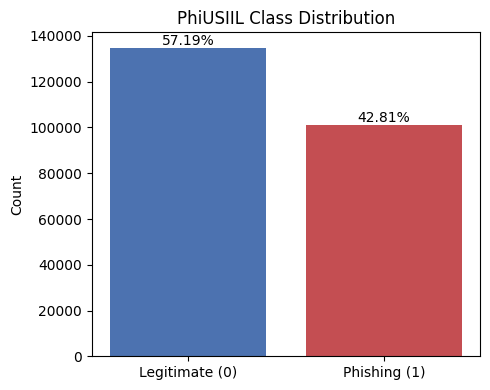

PhiUSIIL: 57.19% legitimate, 42.81% phishing


In [ ]:
p_counts = phiusiil['target'].value_counts().sort_index()
p_total = p_counts.sum()
p_pct = (p_counts / p_total * 100).round(2)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Legitimate (0)', 'Phishing (1)'], p_counts.values, color=['#4C72B0', '#C44E52'])
ax.set_title('PhiUSIIL Class Distribution')
ax.set_ylabel('Count')
for bar, pct in zip(bars, p_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{pct}%',
            ha='center', va='bottom')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/phiusiil_class_distribution.png', dpi=150)
plt.show()

print(f"PhiUSIIL: {p_pct[0]}% legitimate, {p_pct[1]}% phishing")


CELL: class distribution - Vrbancic

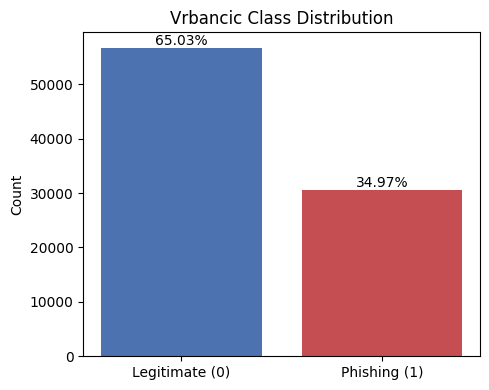

Vrbancic (after dropping duplicates): 65.03% legitimate, 34.97% phishing


In [ ]:
v_counts = vrbancic['target'].value_counts().sort_index()
v_total = v_counts.sum()
v_pct = (v_counts / v_total * 100).round(2)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Legitimate (0)', 'Phishing (1)'], v_counts.values, color=['#4C72B0', '#C44E52'])
ax.set_title('Vrbancic Class Distribution')
ax.set_ylabel('Count')
for bar, pct in zip(bars, v_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{pct}%',
            ha='center', va='bottom')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/vrbancic_class_distribution.png', dpi=150)
plt.show()

print(f"Vrbancic (after dropping duplicates): {v_pct[0]}% legitimate, {v_pct[1]}% phishing")


CELL: feature distributions by class, top features in PhiUSIIL
Ranked by baseline RF importance further down, but this initial list covers the ones most likely to separate classes visually based on describe() from Step 1

/tmp/ipykernel_5029/3162118206.py:16: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(subset.clip(upper=clip_val), ax=axes[i], label=f'Class {label}',
/tmp/ipykernel_5029/3162118206.py:16: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(subset.clip(upper=clip_val), ax=axes[i], label=f'Class {label}',
/tmp/ipykernel_5029/3162118206.py:16: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(subset.clip(upper=clip_val), ax=axes[i], label=f'Class {label}',


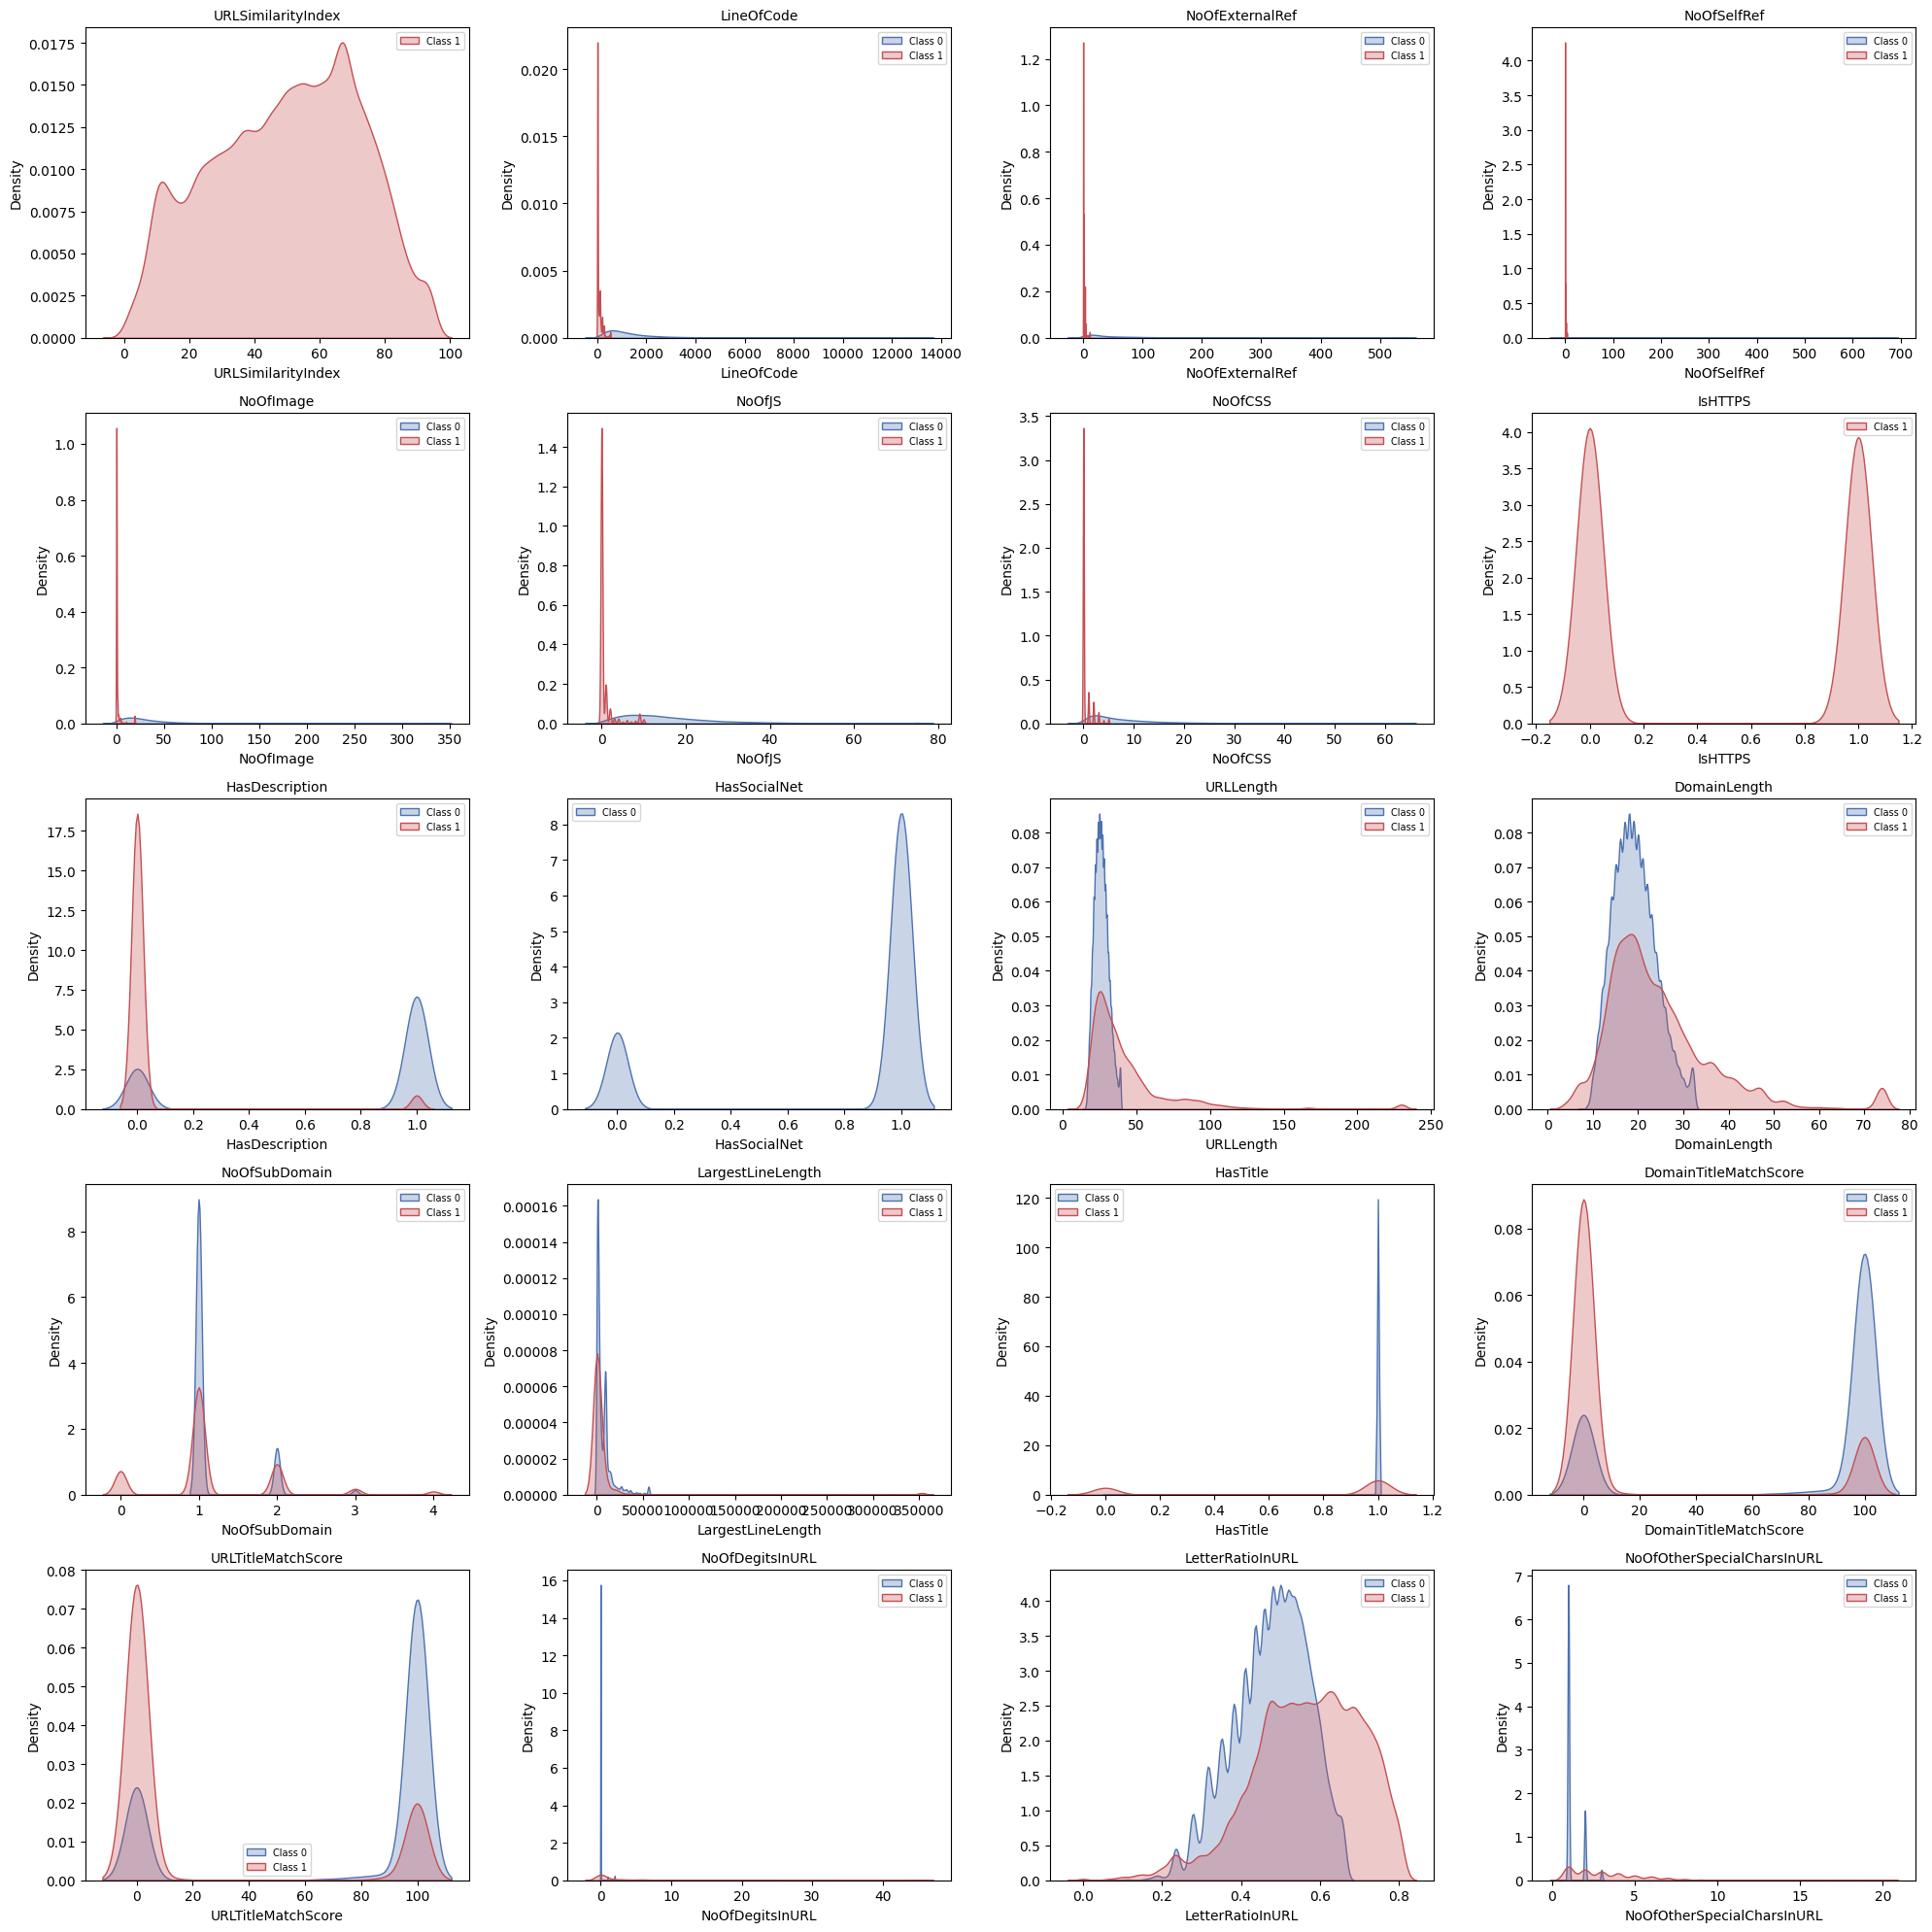

In [ ]:
top_features_phiusiil = [
    'URLSimilarityIndex', 'LineOfCode', 'NoOfExternalRef', 'NoOfSelfRef', 'NoOfImage',
    'NoOfJS', 'NoOfCSS', 'IsHTTPS', 'HasDescription', 'HasSocialNet', 'URLLength',
    'DomainLength', 'NoOfSubDomain', 'LargestLineLength', 'HasTitle',
    'DomainTitleMatchScore', 'URLTitleMatchScore', 'NoOfDegitsInURL',
    'LetterRatioInURL', 'NoOfOtherSpecialCharsInURL',
]

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()
for i, feat in enumerate(top_features_phiusiil):
    for label, color in [(0, '#4C72B0'), (1, '#C44E52')]:
        subset = phiusiil[phiusiil['target'] == label][feat]
        # clip extreme tails just for the plot so the shape near the bulk of data is visible
        clip_val = subset.quantile(0.99)
        sns.kdeplot(subset.clip(upper=clip_val), ax=axes[i], label=f'Class {label}',
                    color=color, fill=True, alpha=0.3)
    axes[i].set_title(feat, fontsize=10)
    axes[i].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/phiusiil_feature_distributions.png', dpi=150)
plt.show()


CELL: boxplots to spot outliers

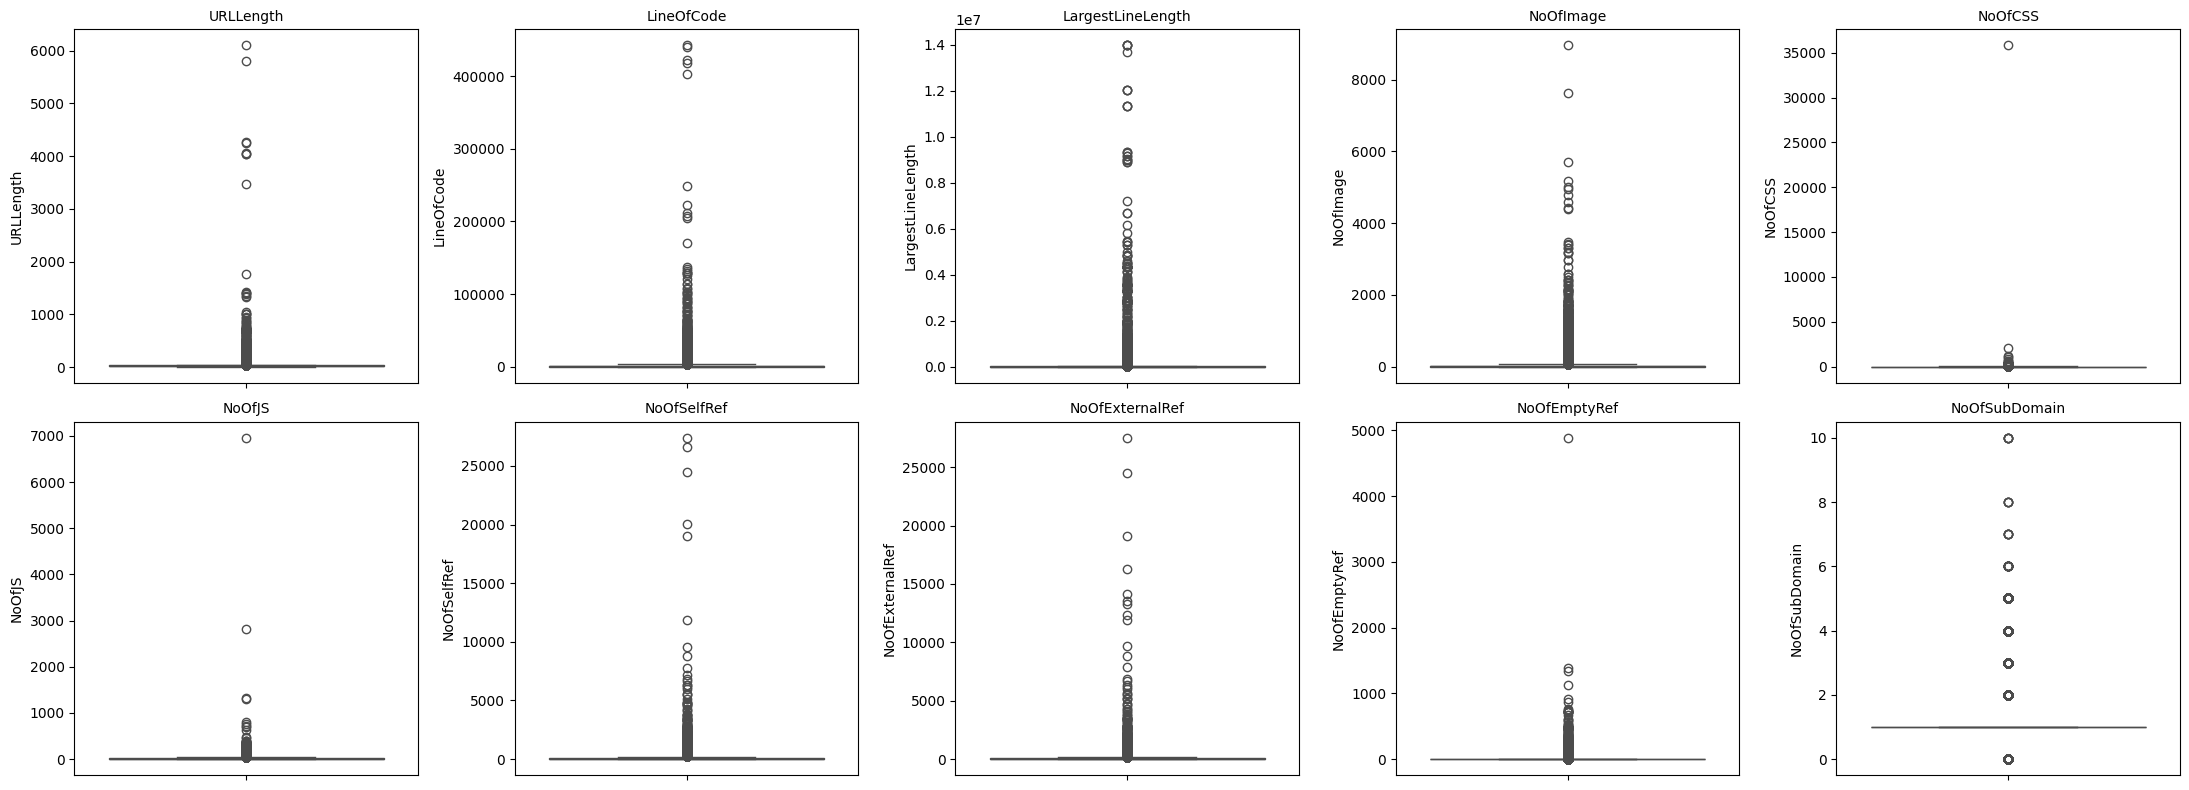

In [ ]:
outlier_check_features = [
    'URLLength', 'LineOfCode', 'LargestLineLength', 'NoOfImage', 'NoOfCSS', 'NoOfJS',
    'NoOfSelfRef', 'NoOfExternalRef', 'NoOfEmptyRef', 'NoOfSubDomain',
]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()
for i, feat in enumerate(outlier_check_features):
    sns.boxplot(y=phiusiil[feat], ax=axes[i], color='#55A868')
    axes[i].set_title(feat, fontsize=10)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/phiusiil_boxplots_outliers.png', dpi=150)
plt.show()


print actual max vs 99th percentile so the outlier gap is documented numerically

In [ ]:
for feat in outlier_check_features:
    p99 = phiusiil[feat].quantile(0.99)
    print(f'{feat}: max = {phiusiil[feat].max()}, 99th percentile = {p99}')

URLLength: max = 6097, 99th percentile = 144.0
LineOfCode: max = 442666, 99th percentile = 10388.0
LargestLineLength: max = 13975732, 99th percentile = 129412.0
NoOfImage: max = 8956, 99th percentile = 243.05999999999767
NoOfCSS: max = 35820, 99th percentile = 51.0
NoOfJS: max = 6957, 99th percentile = 64.0
NoOfSelfRef: max = 27397, 99th percentile = 517.0
NoOfExternalRef: max = 27516, 99th percentile = 423.0
NoOfEmptyRef: max = 4887, 99th percentile = 31.0
NoOfSubDomain: max = 10, 99th percentile = 3.0


CELL: correlation heatmap - PhiUSIIL

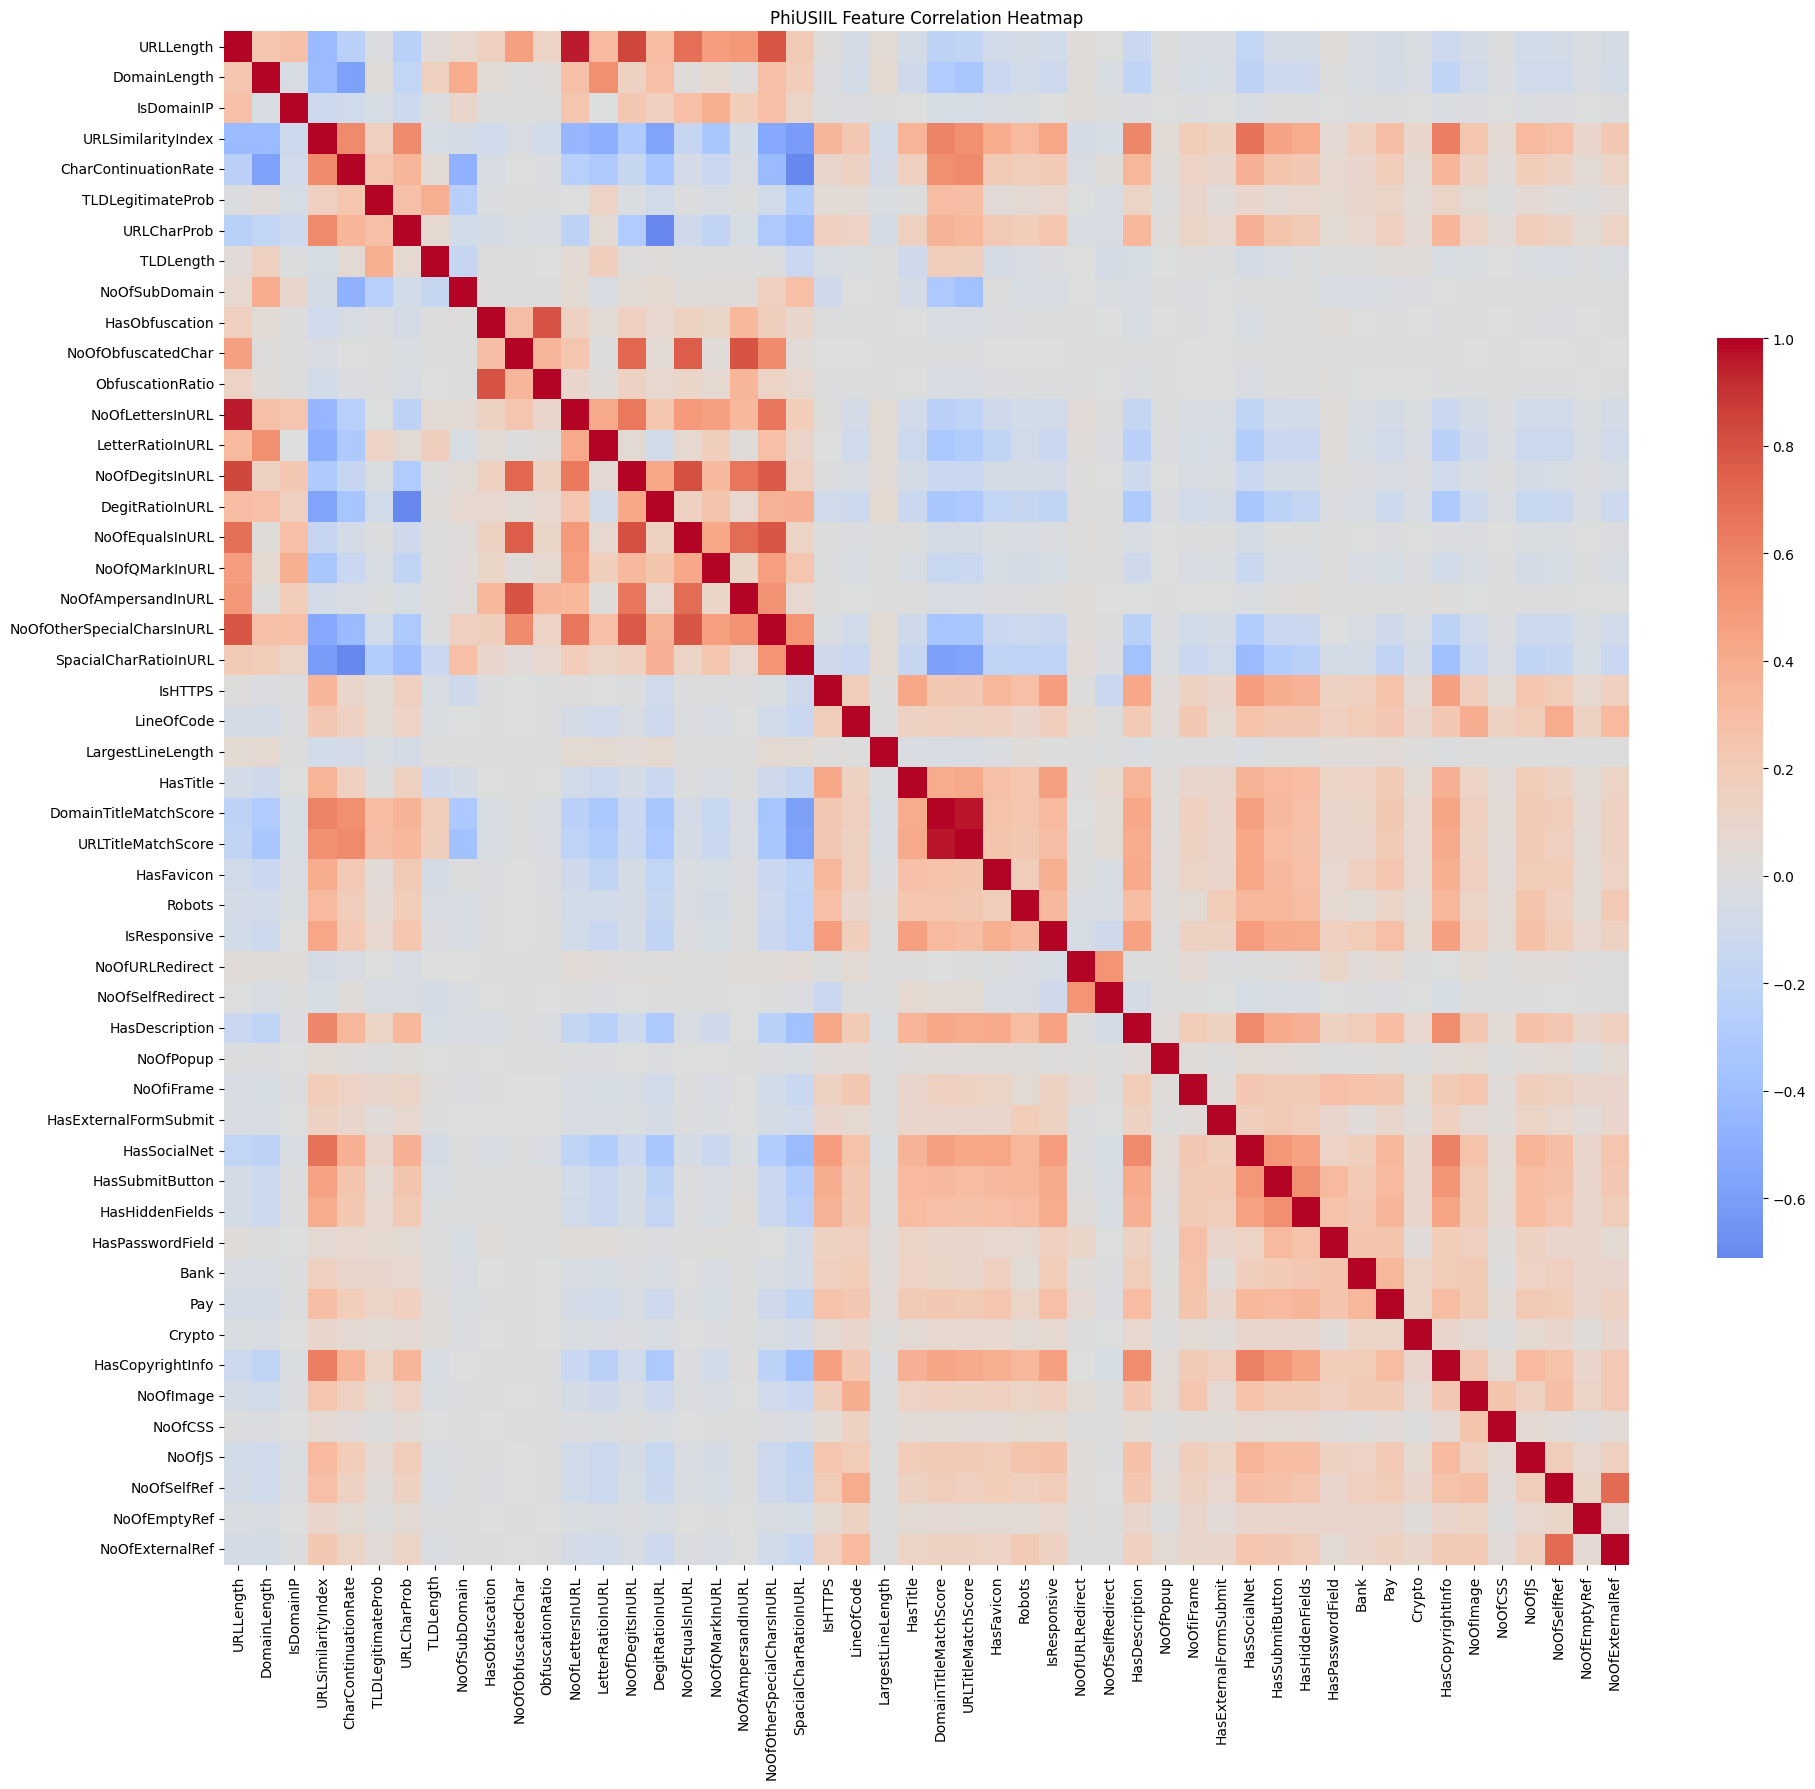

In [ ]:
phiusiil_numeric = phiusiil.select_dtypes(include=[np.number]).drop(columns=['label', 'target'])
corr_p = phiusiil_numeric.corr()

fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(corr_p, cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': 0.6})
ax.set_title('PhiUSIIL Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/phiusiil_correlation_heatmap.png', dpi=150)
plt.show()

list pairs above 0.95 explicitly, since a 53x53 heatmap is too dense to read by eye

In [ ]:
high_corr_pairs = []
cols = corr_p.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        v = abs(corr_p.iloc[i, j])
        if v > 0.95:
            high_corr_pairs.append((cols[i], cols[j], round(v, 4)))
print('PhiUSIIL pairs with |correlation| > 0.95:')
for a, b, v in high_corr_pairs:
    print(f'  {a} <-> {b}: {v}')

PhiUSIIL pairs with |correlation| > 0.95:
  URLLength <-> NoOfLettersInURL: 0.956
  DomainTitleMatchScore <-> URLTitleMatchScore: 0.961


CELL: correlation heatmap - Vrbancic

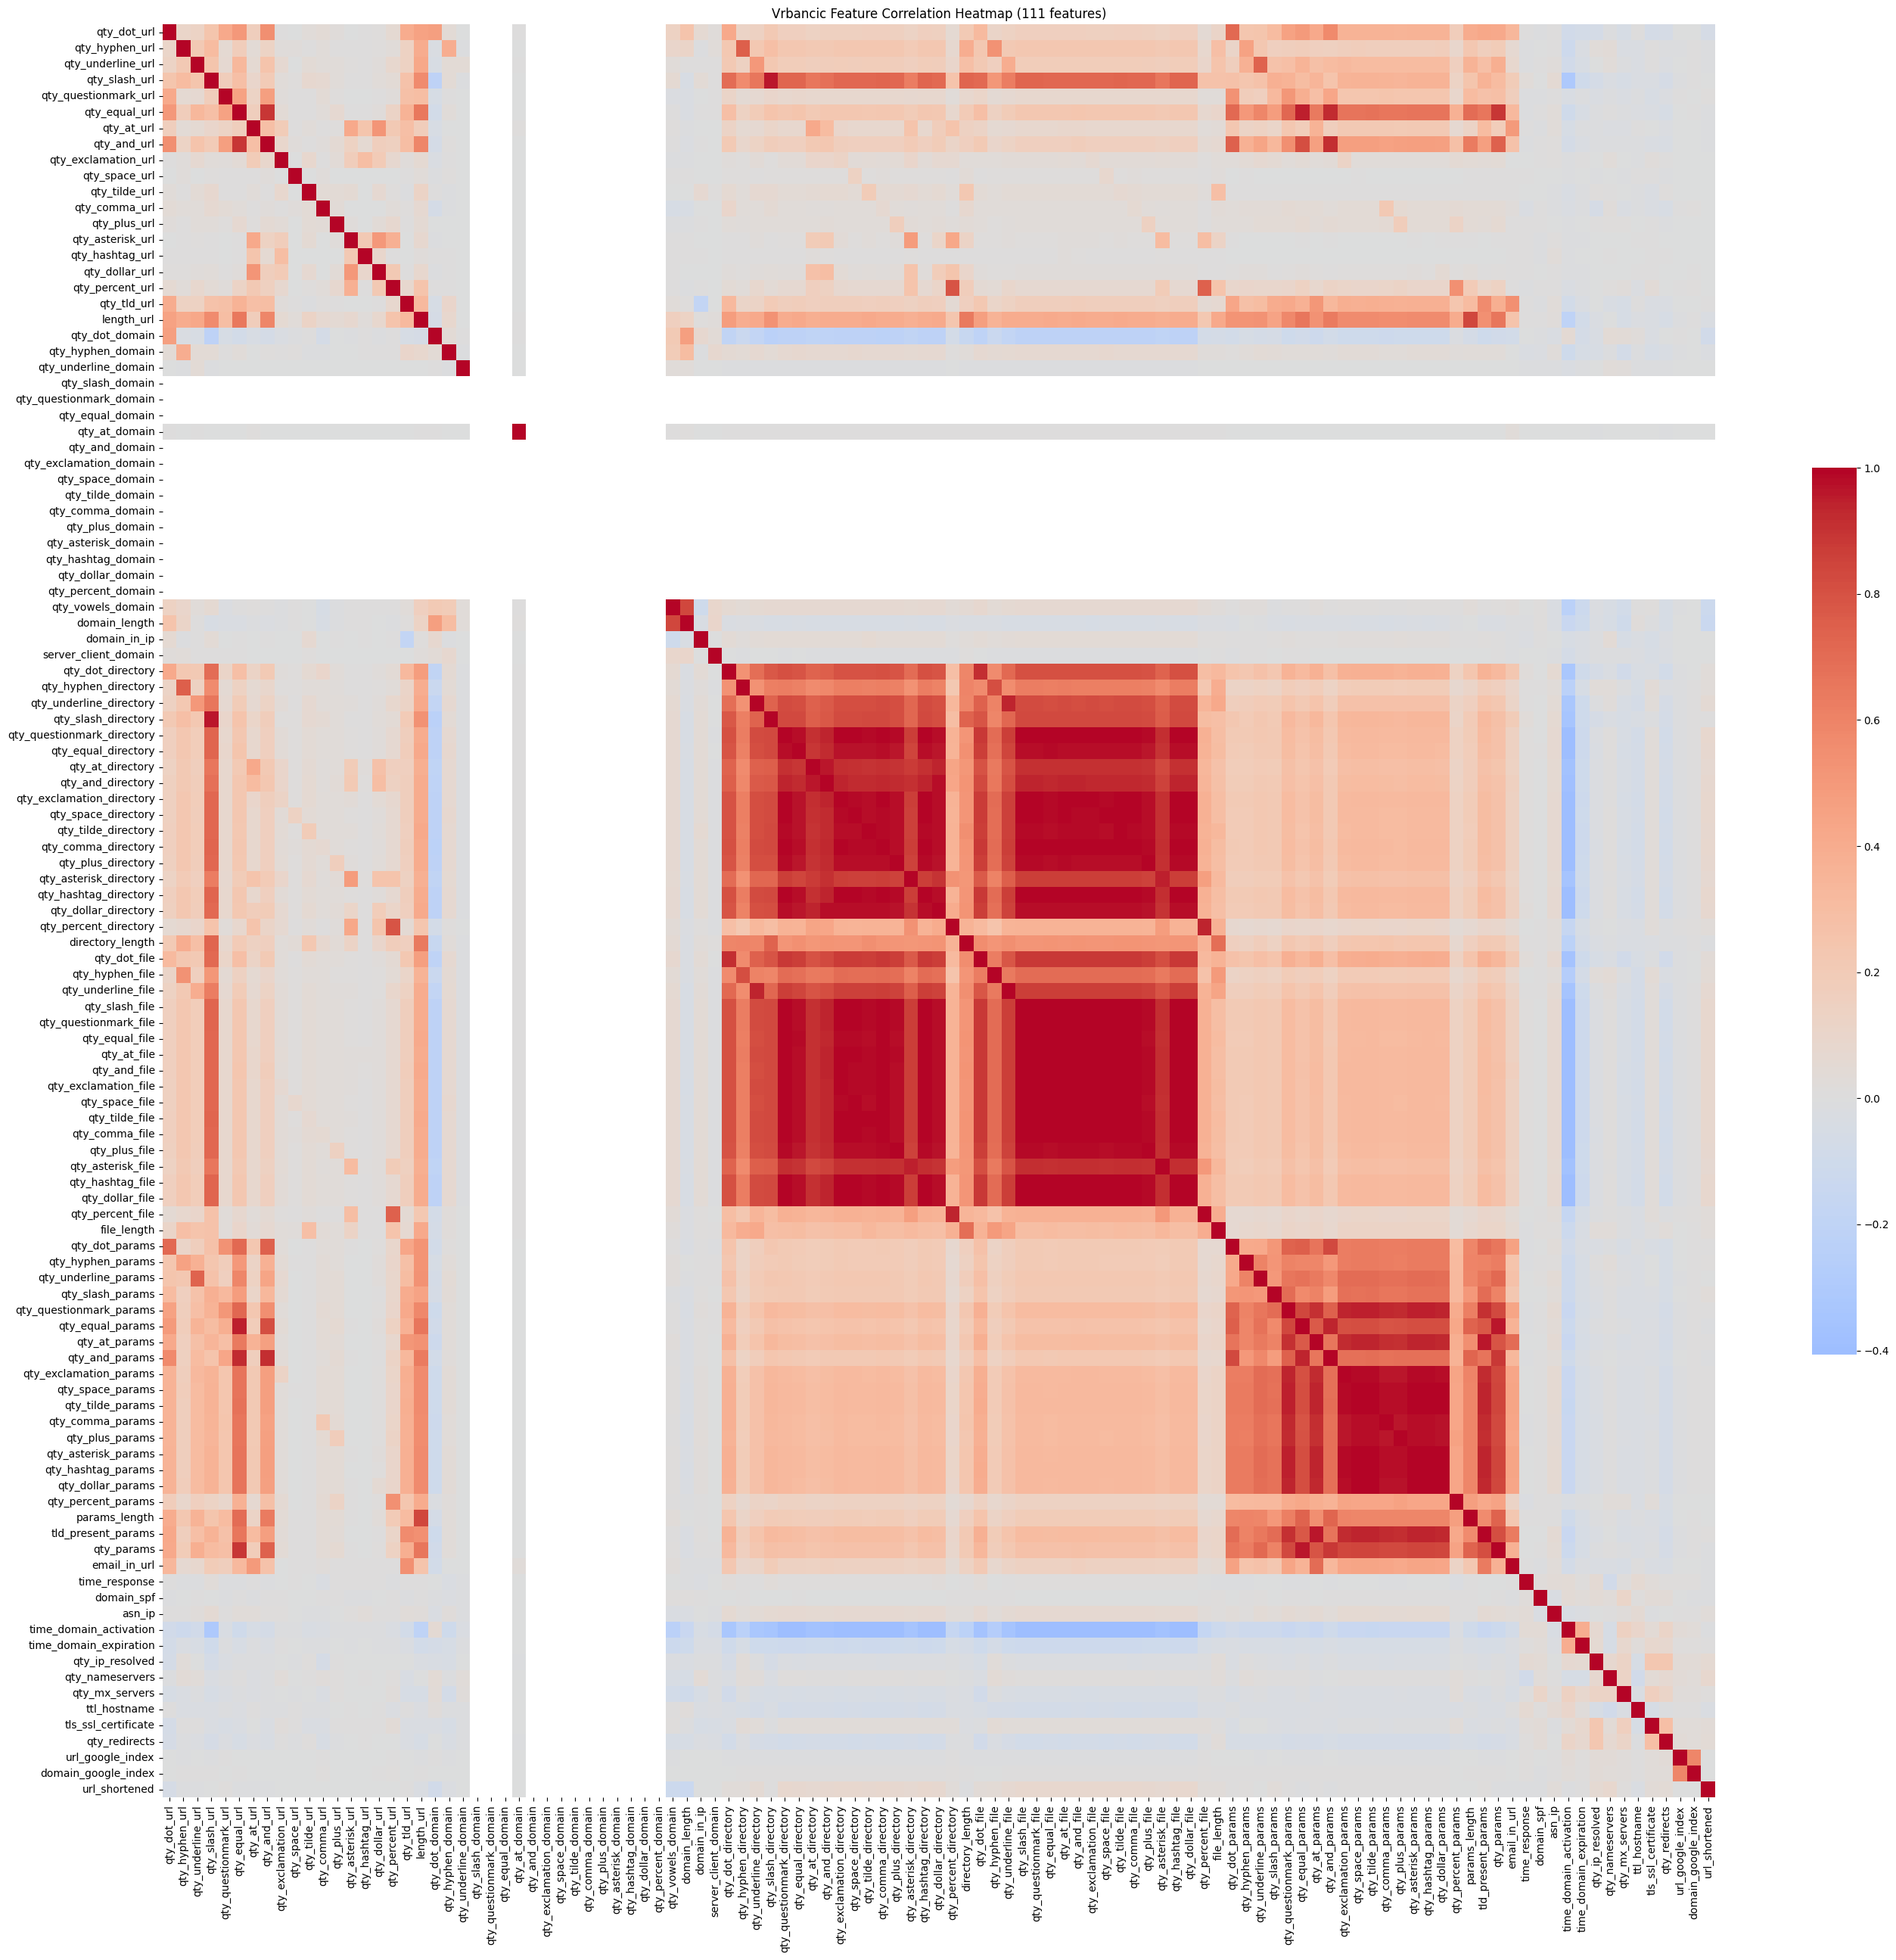

Vrbancic pairs with |correlation| > 0.95: 244 pairs found
First 20:
  qty_slash_url <-> qty_slash_directory: 0.9633
  qty_equal_url <-> qty_equal_params: 0.95
  qty_questionmark_directory <-> qty_equal_directory: 0.9792
  qty_questionmark_directory <-> qty_exclamation_directory: 0.9928
  qty_questionmark_directory <-> qty_space_directory: 0.9911
  qty_questionmark_directory <-> qty_tilde_directory: 0.9881
  qty_questionmark_directory <-> qty_comma_directory: 0.9973
  qty_questionmark_directory <-> qty_plus_directory: 0.9844
  qty_questionmark_directory <-> qty_hashtag_directory: 1.0
  qty_questionmark_directory <-> qty_dollar_directory: 0.9834
  qty_questionmark_directory <-> qty_slash_file: 1.0
  qty_questionmark_directory <-> qty_questionmark_file: 1.0
  qty_questionmark_directory <-> qty_equal_file: 0.995
  qty_questionmark_directory <-> qty_at_file: 0.9994
  qty_questionmark_directory <-> qty_and_file: 0.9969
  qty_questionmark_directory <-> qty_exclamation_file: 0.9976
  qty_quest

In [ ]:
vrbancic_numeric = vrbancic.select_dtypes(include=[np.number]).drop(columns=['phishing', 'target'])
corr_v = vrbancic_numeric.corr()

fig, ax = plt.subplots(figsize=(28, 26))
sns.heatmap(corr_v, cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': 0.5})
ax.set_title('Vrbancic Feature Correlation Heatmap (111 features)')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/vrbancic_correlation_heatmap.png', dpi=150)
plt.show()

high_corr_pairs_v = []
cols_v = corr_v.columns
for i in range(len(cols_v)):
    for j in range(i+1, len(cols_v)):
        v = abs(corr_v.iloc[i, j])
        if v > 0.95:
            high_corr_pairs_v.append((cols_v[i], cols_v[j], round(v, 4)))
print(f'Vrbancic pairs with |correlation| > 0.95: {len(high_corr_pairs_v)} pairs found')
print('First 20:')
for a, b, v in high_corr_pairs_v[:20]:
    print(f'  {a} <-> {b}: {v}')

check how many columns are constant or near-constant, since these drive most of the spurious high-correlation pairs above


In [ ]:
nunique = vrbancic_numeric.nunique()
near_constant_cols = nunique[nunique <= 2].index.tolist()
print()
print(f'Vrbancic columns with 2 or fewer unique values: {len(near_constant_cols)}')
print(near_constant_cols)


Vrbancic columns with 2 or fewer unique values: 26
['qty_slash_domain', 'qty_questionmark_domain', 'qty_equal_domain', 'qty_at_domain', 'qty_and_domain', 'qty_exclamation_domain', 'qty_space_domain', 'qty_tilde_domain', 'qty_comma_domain', 'qty_plus_domain', 'qty_asterisk_domain', 'qty_hashtag_domain', 'qty_dollar_domain', 'qty_percent_domain', 'domain_in_ip', 'server_client_domain', 'qty_questionmark_directory', 'qty_hashtag_directory', 'qty_slash_file', 'qty_questionmark_file', 'qty_hashtag_file', 'qty_dollar_file', 'qty_hashtag_params', 'email_in_url', 'tls_ssl_certificate', 'url_shortened']


CELL: baseline Random Forest feature importance - PhiUSIIL

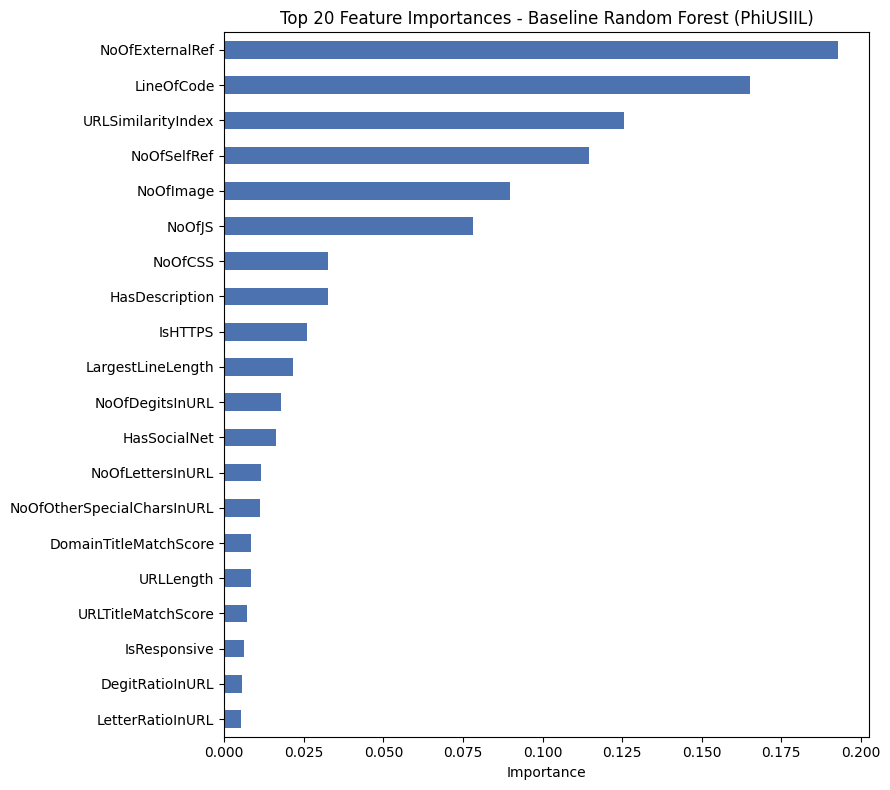

Train accuracy: 1.0
Test accuracy: 1.0

NoOfExternalRef               0.192858
LineOfCode                    0.165017
URLSimilarityIndex            0.125429
NoOfSelfRef                   0.114523
NoOfImage                     0.089752
NoOfJS                        0.078224
NoOfCSS                       0.032718
HasDescription                0.032655
IsHTTPS                       0.025860
LargestLineLength             0.021512
NoOfDegitsInURL               0.017863
HasSocialNet                  0.016281
NoOfLettersInURL              0.011666
NoOfOtherSpecialCharsInURL    0.011355
DomainTitleMatchScore         0.008399
URLLength                     0.008275
URLTitleMatchScore            0.007267
IsResponsive                  0.006123
DegitRatioInURL               0.005709
LetterRatioInURL              0.005263
dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'target']
X = phiusiil.drop(columns=drop_cols)
y = phiusiil['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top20 = importances.head(20)

fig, ax = plt.subplots(figsize=(9, 8))
top20.sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_title('Top 20 Feature Importances - Baseline Random Forest (PhiUSIIL)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/phiusiil_rf_feature_importance.png', dpi=150)
plt.show()

print('Train accuracy:', rf.score(X_train, y_train))
print('Test accuracy:', rf.score(X_test, y_test))
print()
print(top20)


CELL: markdown summary

eda_summary_markdown = """
## EDA Summary

**Class imbalance**
PhiUSIIL: {p_legit}% legitimate, {p_phish}% phishing (mild imbalance)
Vrbancic (after dropping 1438 duplicates): {v_legit}% legitimate, {v_phish}% phishing (moderate imbalance)

**Feature distributions**
Several PhiUSIIL features show visibly different distributions by class, especially
URLSimilarityIndex, LineOfCode, NoOfExternalRef, and NoOfSelfRef — legitimate and
phishing URLs separate cleanly on these even before modeling.

**Outliers**
URLLength, LineOfCode, and LargestLineLength all have extreme right-tail outliers
(max values thousands of times the 99th percentile). These need capping or
log-transformation before modeling with algorithms sensitive to scale.

**Correlation**
PhiUSIIL: only 2 feature pairs exceed 0.95 correlation (DomainTitleMatchScore/
URLTitleMatchScore, and URLLength/NoOfLettersInURL). Low redundancy overall.
Vrbancic: 244 feature pairs exceed 0.95 correlation, almost all driven by columns
that are constant or near-constant (26+ columns have 2 or fewer unique values,
mostly the qty_*_domain character-count columns). These near-constant columns carry
little to no signal and are strong candidates for removal before modeling.

**Baseline Random Forest (PhiUSIIL)**
Top features by importance: NoOfExternalRef, LineOfCode, URLSimilarityIndex,
NoOfSelfRef, NoOfImage, NoOfJS. Model reached {test_acc}% test accuracy at only
50 trees — flag this as a possible sign the task is close to saturated on this
dataset, or that URLSimilarityIndex alone is doing most of the work (it's a
similarity score built by the dataset creators, so it may be closer to a label
proxy than a raw feature).

**Data quality issues carried over from Step 1**
Vrbancic has 1438 duplicate rows and -1 sentinel values in qty_redirects,
url_google_index, and domain_google_index (6949, 90, and 88 rows respectively)
that are not caught by isnull() and need explicit handling.
""".format(
    p_legit=p_pct[0], p_phish=p_pct[1],
    v_legit=v_pct[0], v_phish=v_pct[1],
    test_acc=round(rf.score(X_test, y_test) * 100, 2),
)



Step 3: Preprocessing

CELL: install SMOTE support

In [ ]:
!pip install imbalanced-learn --quiet

CELL: duplicates

In [ ]:
print('Before dedup:', phiusiil.shape, vrbancic.shape)
phiusiil = phiusiil.drop_duplicates()
vrbancic = vrbancic.drop_duplicates()
print('After dedup:', phiusiil.shape, vrbancic.shape)

print('Duplicate check after drop:')
print('PhiUSIIL:', phiusiil.duplicated().sum())
print('Vrbancic:', vrbancic.duplicated().sum())

Before dedup: (235795, 57) (87209, 113)
After dedup: (235795, 57) (87209, 113)
Duplicate check after drop:
PhiUSIIL: 0
Vrbancic: 0


CELL: fix -1 sentinel values in Vrbancic before missing-value handling
.isnull().sum() will not catch these, since they are not NaN, they are a real -1 meaning "could not be resolved" (found in Step 1: qty_redirects, url_google_index, domain_google_index). Converting to NaN first lets the missing-value rules below apply correctly instead of silently treating -1 as a real numeric value.


In [ ]:
import numpy as np

sentinel_cols = ['qty_redirects', 'url_google_index', 'domain_google_index']
for col in sentinel_cols:
    vrbancic[col] = vrbancic[col].replace(-1, np.nan)

miss_pct = vrbancic.isnull().mean() * 100
print('Vrbancic missing % after sentinel fix (only affected columns shown):')
print(miss_pct[miss_pct > 0])

Vrbancic missing % after sentinel fix (only affected columns shown):
qty_redirects          6.320449
url_google_index       0.075680
domain_google_index    0.073387
dtype: float64


CELL: missing value handling (apply the 1% / 30% thresholds)

In [ ]:
for col in vrbancic.columns:
    pct = miss_pct[col]
    if 0 < pct < 1:
        vrbancic = vrbancic.dropna(subset=[col])
    elif 1 <= pct <= 30:
        if vrbancic[col].dtype == 'object':
            vrbancic[col] = vrbancic[col].fillna(vrbancic[col].mode()[0])
        else:
            vrbancic[col] = vrbancic[col].fillna(vrbancic[col].median())
    elif pct > 30:
        vrbancic = vrbancic.drop(columns=[col])

In [ ]:
# PhiUSIIL had zero missing values in Step 1, nothing to do there, but verify anyway
print('PhiUSIIL remaining nulls:', phiusiil.isnull().sum().sum())
print('Vrbancic remaining nulls:', vrbancic.isnull().sum().sum())
print('Vrbancic shape after missing value handling:', vrbancic.shape)


PhiUSIIL remaining nulls: 0
Vrbancic remaining nulls: 0
Vrbancic shape after missing value handling: (87141, 113)


CELL: encoding - drop identifier/text columns, confirm rest is numeric
FILENAME, URL, Domain, Title are identifiers or raw text, not model features - their signal is already captured numerically elsewhere (URLLength, DomainLength, DomainTitleMatchScore, etc). TLD is dropped too since one-hot encoding it would add hundreds of sparse columns when TLDLength and TLDLegitimateProb already derive from it.


In [ ]:
identifier_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label']
phiusiil_model = phiusiil.drop(columns=[c for c in identifier_cols if c in phiusiil.columns])

print('PhiUSIIL non-numeric columns remaining:', list(phiusiil_model.select_dtypes(include='object').columns))
print('Vrbancic non-numeric columns remaining:', list(vrbancic.select_dtypes(include='object').columns))
# both should print an empty list - Vrbancic had no object columns from the start (Step 1),
# and PhiUSIIL's only object columns were the ones just dropped

PhiUSIIL non-numeric columns remaining: []
Vrbancic non-numeric columns remaining: []


CELL: feature and target separation

In [ ]:
X = phiusiil_model.drop(columns=['target'])
y = phiusiil_model['target']

print('X shape:', X.shape, 'y shape:', y.shape)
print('y unique values:', sorted(y.unique()))

X shape: (235795, 50) y shape: (235795,)
y unique values: [np.int64(0), np.int64(1)]


CELL: train-test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('y_train distribution:')
print(y_train.value_counts(normalize=True).round(4))
print('y_test distribution:')
print(y_test.value_counts(normalize=True).round(4))

X_train: (188636, 50) X_test: (47159, 50)
y_train distribution:
target
0    0.5719
1    0.4281
Name: proportion, dtype: float64
y_test distribution:
target
0    0.5719
1    0.4281
Name: proportion, dtype: float64


 CELL: outlier capping (fit on X_train only, applied to both) ----
From Step 2: URLLength, LineOfCode, LargestLineLength, NoOfImage, NoOfCSS, NoOfJS,NoOfSelfRef, NoOfExternalRef, NoOfEmptyRef all have extreme right-tail outliers (max values thousands of times the 99th percentile). StandardScaler is mean/std based, so these need capping first or a handful of rows will dominate the scale.
The 99th percentile is computed from X_train only, then applied to X_test - this happens after the split (not before) so no information from the test set leaks into the cap threshold.


In [ ]:
outlier_cols = [
    'URLLength', 'LineOfCode', 'LargestLineLength', 'NoOfImage', 'NoOfCSS', 'NoOfJS',
    'NoOfSelfRef', 'NoOfExternalRef', 'NoOfEmptyRef',
]
X_train = X_train.copy()
X_test = X_test.copy()
for col in outlier_cols:
    cap = X_train[col].quantile(0.99)  # threshold from training data only
    X_train[col] = X_train[col].clip(upper=cap)
    X_test[col] = X_test[col].clip(upper=cap)  # same threshold applied, not refit

print('Outlier columns capped at 99th percentile (threshold from X_train only):', outlier_cols)

Outlier columns capped at 99th percentile (threshold from X_train only): ['URLLength', 'LineOfCode', 'LargestLineLength', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfExternalRef', 'NoOfEmptyRef']


CELL: scaling - main scaler on full PhiUSIIL feature set

In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()
scaler.fit(X_train)  # fit on X_train only, never on X_test

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, f'{DATA_DIR}/scaler.pkl')
print('Main scaler (all', X_train.shape[1], 'features) saved to', f'{DATA_DIR}/scaler.pkl')

Main scaler (all 50 features) saved to /content/drive/MyDrive/Phishing Detection Project/scaler.pkl


CELL: scaling - second scaler for cross-dataset testing on Vrbancic ----
The main scaler above was fit on ~51 PhiUSIIL columns. Vrbancic only shares 8 concepts with PhiUSIIL (from Step 1), so the main scaler cannot transform an 8-column dataframe - shapes won't match. A second scaler, fit only on those same 8 PhiUSIIL columns, is the only way to keep "never refit on Vrbancic" both true and dimensionally possible.


In [ ]:

common_feature_map = {
    'url_length':          ('URLLength', 'length_url'),
    'domain_length':       ('DomainLength', 'domain_length'),
    'domain_is_ip':        ('IsDomainIP', 'domain_in_ip'),
    'https_or_ssl':        ('IsHTTPS', 'tls_ssl_certificate'),
    'redirect_count':      ('NoOfURLRedirect', 'qty_redirects'),
    'equal_sign_count':    ('NoOfEqualsInURL', 'qty_equal_url'),
    'question_mark_count': ('NoOfQMarkInURL', 'qty_questionmark_url'),
    'ampersand_count':     ('NoOfAmpersandInURL', 'qty_and_url'),
}

phiusiil_common_cols = [v[0] for v in common_feature_map.values()]
vrbancic_common_cols = [v[1] for v in common_feature_map.values()]

X_train_common = X_train[phiusiil_common_cols]
X_test_common = X_test[phiusiil_common_cols]

cross_scaler = StandardScaler()
cross_scaler.fit(X_train_common)  # fit only on PhiUSIIL's 8-column training subset

joblib.dump(cross_scaler, f'{DATA_DIR}/cross_scaler.pkl')

X_test_common_scaled = cross_scaler.transform(X_test_common)

 align Vrbancic's 8 matching columns, rename to the same concept names, then transform using the already-fitted cross_scaler - never refit


In [ ]:
X_cross = vrbancic[vrbancic_common_cols].rename(
    columns=dict(zip(vrbancic_common_cols, phiusiil_common_cols))
)
X_cross = X_cross[phiusiil_common_cols]  # enforce identical column order
y_cross = vrbancic['target']

X_cross_scaled = cross_scaler.transform(X_cross)

print('Cross-dataset scaler saved. Shapes:')
print('X_test_common_scaled (PhiUSIIL, 8 features):', X_test_common_scaled.shape)
print('X_cross_scaled (Vrbancic, 8 features):', X_cross_scaled.shape)

Cross-dataset scaler saved. Shapes:
X_test_common_scaled (PhiUSIIL, 8 features): (47159, 8)
X_cross_scaled (Vrbancic, 8 features): (87141, 8)


CELL: class imbalance - SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print('Before SMOTE:', pd.Series(y_train).value_counts().to_dict())
print('After SMOTE:', pd.Series(y_train_smote).value_counts().to_dict())

Before SMOTE: {0: 107880, 1: 80756}
After SMOTE: {0: 107880, 1: 107880}


CELL: save everything

In [ ]:
import pandas as pd

np.save(f'{DATA_DIR}/X_train.npy', X_train_scaled)
np.save(f'{DATA_DIR}/X_test.npy', X_test_scaled)
np.save(f'{DATA_DIR}/y_train.npy', y_train.values)
np.save(f'{DATA_DIR}/y_test.npy', y_test.values)

np.save(f'{DATA_DIR}/X_train_smote.npy', X_train_smote)
np.save(f'{DATA_DIR}/y_train_smote.npy', y_train_smote)

np.save(f'{DATA_DIR}/X_cross.npy', X_cross_scaled)
np.save(f'{DATA_DIR}/y_cross.npy', y_cross.values)

print('All files saved to', DATA_DIR)

All files saved to /content/drive/MyDrive/Phishing Detection Project


CELL: verify saved files load correctly

In [ ]:
files_to_check = [
    'X_train.npy', 'X_test.npy', 'y_train.npy', 'y_test.npy',
    'X_train_smote.npy', 'y_train_smote.npy', 'X_cross.npy', 'y_cross.npy',
]
for fname in files_to_check:
    arr = np.load(f'{DATA_DIR}/{fname}')
    print(f'{fname}: shape {arr.shape}, dtype {arr.dtype}')

X_train.npy: shape (188636, 50), dtype float64
X_test.npy: shape (47159, 50), dtype float64
y_train.npy: shape (188636,), dtype int64
y_test.npy: shape (47159,), dtype int64
X_train_smote.npy: shape (215760, 50), dtype float64
y_train_smote.npy: shape (215760,), dtype int64
X_cross.npy: shape (87141, 8), dtype float64
y_cross.npy: shape (87141,), dtype int64


Step 4: Feature Engineering & Selection

the main model here uses ONLY the 22 URL-lexical features - features computable from the URL string alone, no page load needed. This satisfies the Chrome-extension real-time requirement directly, and sidesteps the checklist conflict where "20-30 features" and "must exist in Vrbancic" cannot both be true (Vrbancic only shares 8 concepts with PhiUSIIL total). The 8-feature cross-dataset generalization check built in Step 3 (X_cross.npy, cross_scaler.pkl) stays separate and untouched - it is a smaller, secondary experiment, not reduced to this step's SELECTED_FEATURES list.


In [ ]:
# ---- CELL: restrict to URL-lexical candidate pool ----
url_lexical_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain',
    'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb',
    'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL',
    'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL',
    'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
    'SpacialCharRatioInURL', 'IsHTTPS',
]

X_train_url = X_train[url_lexical_features].copy()
X_test_url = X_test[url_lexical_features].copy()

print('Candidate pool size:', len(url_lexical_features))

# ---- CELL: correlation-based removal ----
corr = X_train_url.corr().abs()
cols = corr.columns
high_corr_pairs = []
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        v = corr.iloc[i, j]
        if v > 0.95:
            high_corr_pairs.append((cols[i], cols[j], round(v, 4)))

print('Pairs with |correlation| > 0.95 in the URL-lexical pool:', high_corr_pairs)


Candidate pool size: 22
Pairs with |correlation| > 0.95 in the URL-lexical pool: []


 whichever feature correlates more strongly with the target and drop the other. On this data, no pairs exceeded 0.95 once outlier capping and the proper train/test split were applied - loop below only acts if your own run finds any.


In [ ]:
target_corr = X_train_url.apply(lambda c: abs(np.corrcoef(c, y_train)[0, 1]))
dropped_for_correlation = []
for a, b, v in high_corr_pairs:
    weaker = a if target_corr[a] < target_corr[b] else b
    if weaker not in dropped_for_correlation:
        dropped_for_correlation.append(weaker)

X_train_url = X_train_url.drop(columns=dropped_for_correlation)
X_test_url = X_test_url.drop(columns=dropped_for_correlation)

print('Dropped for correlation:', dropped_for_correlation)
print('Remaining after correlation removal:', X_train_url.shape[1])


Dropped for correlation: []
Remaining after correlation removal: 22


RF importances:
URLSimilarityIndex            4.457706e-01
IsHTTPS                       1.851128e-01
NoOfOtherSpecialCharsInURL    8.228185e-02
DegitRatioInURL               6.050514e-02
NoOfDegitsInURL               5.580018e-02
LetterRatioInURL              3.407822e-02
URLLength                     3.332067e-02
SpacialCharRatioInURL         2.187628e-02
NoOfLettersInURL              1.930448e-02
NoOfSubDomain                 1.530855e-02
URLCharProb                   1.485409e-02
CharContinuationRate          1.381625e-02
TLDLegitimateProb             9.669541e-03
DomainLength                  5.164184e-03
TLDLength                     2.747354e-03
NoOfQMarkInURL                3.717216e-04
HasObfuscation                1.456947e-05
NoOfAmpersandInURL            2.218652e-06
NoOfEqualsInURL               9.924591e-07
IsDomainIP                    2.243021e-07
ObfuscationRatio              8.874866e-08
NoOfObfuscatedChar            0.000000e+00
dtype: float64
Test accuracy on URL-le

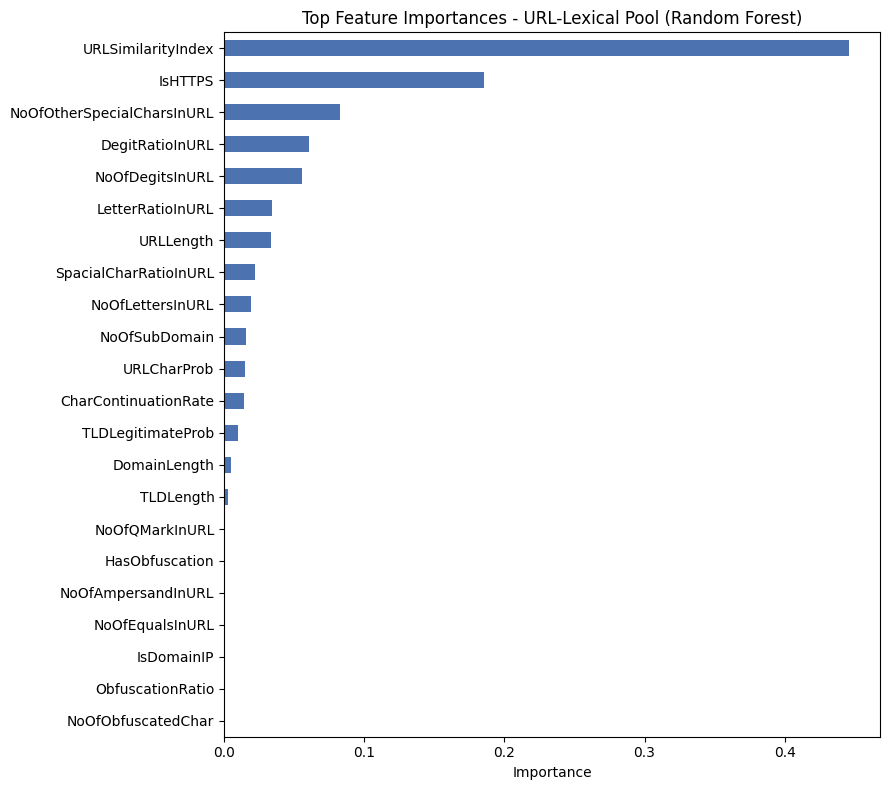

In [ ]:
 # CELL: Random Forest feature importance
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_url, y_train)

importances = pd.Series(rf.feature_importances_, index=X_train_url.columns).sort_values(ascending=False)
print('RF importances:')
print(importances)
print('Test accuracy on URL-lexical features only:', rf.score(X_test_url, y_test))

top_n_plot = importances.head(30)
fig, ax = plt.subplots(figsize=(9, 8))
top_n_plot.sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_title('Top Feature Importances - URL-Lexical Pool (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/eda_plots/step4_rf_importance_url_lexical.png', dpi=150)
plt.show()

In [ ]:
# ---- CELL: Recursive Feature Elimination ----
from sklearn.feature_selection import RFE

# pool only has ~20-22 candidates after correlation removal, so 30 isn't reachable -
# select 20, matching the low end of the checklist's 20-30 target
n_select = min(20, X_train_url.shape[1])

rfe = RFE(
    estimator=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    n_features_to_select=n_select,
)
rfe.fit(X_train_url, y_train)
rfe_selected = X_train_url.columns[rfe.support_].tolist()

print(f'RFE selected ({n_select} features):', rfe_selected)

RFE selected (20 features): ['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']


In [ ]:
# ---- CELL: compare RF top vs RFE selected ----
rf_top = importances.head(n_select).index.tolist()

overlap = set(rfe_selected) & set(rf_top)
union = set(rfe_selected) | set(rf_top)

print(f'RF top {n_select}:', rf_top)
print(f'Overlap between RF top and RFE selected: {len(overlap)} of {n_select}')
print('Union of both methods:', len(union), 'features ->', sorted(union))

RF top 20: ['URLSimilarityIndex', 'IsHTTPS', 'NoOfOtherSpecialCharsInURL', 'DegitRatioInURL', 'NoOfDegitsInURL', 'LetterRatioInURL', 'URLLength', 'SpacialCharRatioInURL', 'NoOfLettersInURL', 'NoOfSubDomain', 'URLCharProb', 'CharContinuationRate', 'TLDLegitimateProb', 'DomainLength', 'TLDLength', 'NoOfQMarkInURL', 'HasObfuscation', 'NoOfAmpersandInURL', 'NoOfEqualsInURL', 'IsDomainIP']
Overlap between RF top and RFE selected: 19 of 20
Union of both methods: 21 features -> ['CharContinuationRate', 'DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS', 'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLegitimateProb', 'TLDLength', 'URLCharProb', 'URLLength', 'URLSimilarityIndex']


In [ ]:
# ---- CELL: final feature list ----
# Using the union of RF importance and RFE, since both methods largely agree (verified: 19 of 20 overlap on this data) and the union naturally lands in the
# 20-30 range the checklist asks for, without needing to force it.
SELECTED_FEATURES = sorted(union)

print(f'Final feature list: {len(SELECTED_FEATURES)} features')
print(SELECTED_FEATURES)

Final feature list: 21 features
['CharContinuationRate', 'DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS', 'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLegitimateProb', 'TLDLength', 'URLCharProb', 'URLLength', 'URLSimilarityIndex']


In [ ]:
# critical check: since these are all drawn from the URL-lexical pool by design, # and 8 of the URL-lexical features are known (from Step 1) to have a Vrbancic
# equivalent, confirm how many of the FINAL list actually overlap with Vrbancic - # this is informational for the paper, not a filter, since Path B keeps the
# cross-dataset check as its own separate 8-feature model (Step 3's X_cross.npy)

vrbancic_shared_concepts = ['URLLength', 'DomainLength', 'IsDomainIP', 'IsHTTPS',
                             'NoOfURLRedirect', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
                             'NoOfAmpersandInURL']
overlap_with_vrbancic = [f for f in SELECTED_FEATURES if f in vrbancic_shared_concepts]
print(f'Of these {len(SELECTED_FEATURES)} features, {len(overlap_with_vrbancic)} also exist in Vrbancic:', overlap_with_vrbancic)
print('Reminder: cross-dataset generalization is tested separately using the 8-feature')
print('X_cross.npy / cross_scaler.pkl from Step 3, not by filtering this list further.')

Of these 21 features, 7 also exist in Vrbancic: ['DomainLength', 'IsDomainIP', 'IsHTTPS', 'NoOfAmpersandInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'URLLength']
Reminder: cross-dataset generalization is tested separately using the 8-feature
X_cross.npy / cross_scaler.pkl from Step 3, not by filtering this list further.


In [ ]:
# ---- CELL: save config.py ----
config_content = f'''SELECTED_FEATURES = {SELECTED_FEATURES}
RANDOM_STATE = 42
TEST_SIZE = 0.2
'''

with open(f'{DATA_DIR}/config.py', 'w') as f:
    f.write(config_content)

print('config.py saved to', f'{DATA_DIR}/config.py')
print(config_content)

config.py saved to /content/drive/MyDrive/Phishing Detection Project/config.py
SELECTED_FEATURES = ['CharContinuationRate', 'DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS', 'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLegitimateProb', 'TLDLength', 'URLCharProb', 'URLLength', 'URLSimilarityIndex']
RANDOM_STATE = 42
TEST_SIZE = 0.2



In [ ]:
# ---- CELL: reduce X_train/X_test to selected features, rescale, resave ----
# Note: the original scaler.pkl from Step 3 was fit on all 50 features. Since the # final model only uses these 21 (or however many your run selects), a new scaler
# fit on just these columns is needed - fit on X_train only, as always.
from sklearn.preprocessing import StandardScaler
import joblib

X_train_final = X_train[SELECTED_FEATURES]
X_test_final = X_test[SELECTED_FEATURES]

final_scaler = StandardScaler()
final_scaler.fit(X_train_final)
X_train_final_scaled = final_scaler.transform(X_train_final)
X_test_final_scaled = final_scaler.transform(X_test_final)

joblib.dump(final_scaler, f'{DATA_DIR}/final_scaler.pkl')

np.save(f'{DATA_DIR}/X_train_selected.npy', X_train_final_scaled)
np.save(f'{DATA_DIR}/X_test_selected.npy', X_test_final_scaled)

print('Saved X_train_selected.npy:', X_train_final_scaled.shape)
print('Saved X_test_selected.npy:', X_test_final_scaled.shape)
print('Saved final_scaler.pkl for the', len(SELECTED_FEATURES), 'selected features')

Saved X_train_selected.npy: (188636, 21)
Saved X_test_selected.npy: (47159, 21)
Saved final_scaler.pkl for the 21 selected features


In [ ]:
# ---- CELL: confirm shapes match expectations ----
X_train_selected_check = np.load(f'{DATA_DIR}/X_train_selected.npy')
X_test_selected_check = np.load(f'{DATA_DIR}/X_test_selected.npy')
X_cross_check = np.load(f'{DATA_DIR}/X_cross.npy')  # unchanged from Step 3, still 8 features

print('X_train_selected:', X_train_selected_check.shape, '- expected (', X_train.shape[0], ',', len(SELECTED_FEATURES), ')')
print('X_test_selected:', X_test_selected_check.shape, '- expected (', X_test.shape[0], ',', len(SELECTED_FEATURES), ')')
print('X_cross (Step 3, untouched, separate 8-feature generalization check):', X_cross_check.shape)

X_train_selected: (188636, 21) - expected ( 188636 , 21 )
X_test_selected: (47159, 21) - expected ( 47159 , 21 )
X_cross (Step 3, untouched, separate 8-feature generalization check): (87141, 8)


Step 5: Model Building

In [ ]:
 # ---- CELL: install XGBoost and CatBoost ----
!pip install xgboost catboost --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.1 MB/s eta 0:00:00


In [ ]:
# ---- CELL: load the selected-feature training data ----
import numpy as np
import pandas as pd

In [ ]:
X_train_selected = np.load(f'{DATA_DIR}/X_train_selected.npy')
X_test_selected = np.load(f'{DATA_DIR}/X_test_selected.npy')
y_train = np.load(f'{DATA_DIR}/y_train.npy')
y_test = np.load(f'{DATA_DIR}/y_test.npy')

print('X_train_selected:', X_train_selected.shape)
print('X_test_selected:', X_test_selected.shape)
print('y_train:', y_train.shape, 'y_test:', y_test.shape)

X_train_selected: (188636, 21)
X_test_selected: (47159, 21)
y_train: (188636,) y_test: (47159,)


In [ ]:
# ---- CELL: shared evaluation helper ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = {}

def evaluate_model(name, model, X_te, y_te):
    preds = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    scores = {
        'accuracy': accuracy_score(y_te, preds),
        'precision': precision_score(y_te, preds),
        'recall': recall_score(y_te, preds),
        'f1': f1_score(y_te, preds),
        'roc_auc': roc_auc_score(y_te, proba),
    }
    results[name] = scores
    print(f'{name}:')
    for k, v in scores.items():
        print(f'  {k}: {v:.4f}')
    return scores

In [ ]:
# ---- CELL: Logistic Regression (baseline) ----
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_selected, y_train)
evaluate_model('Logistic Regression', log_reg, X_test_selected, y_test)

Logistic Regression:
  accuracy: 0.9998
  precision: 1.0000
  recall: 0.9995
  f1: 0.9997
  roc_auc: 0.9999


{'accuracy': 0.9997667465383065,
 'precision': 1.0,
 'recall': 0.9994551488434296,
 'f1': 0.9997275001857954,
 'roc_auc': np.float64(0.9999303779873449)}

In [ ]:
# ---- CELL: Random Forest ----
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_selected, y_train)
evaluate_model('Random Forest', rf_model, X_test_selected, y_test)

Random Forest:
  accuracy: 0.9999
  precision: 1.0000
  recall: 0.9998
  f1: 0.9999
  roc_auc: 0.9999


{'accuracy': 0.9999151805593842,
 'precision': 1.0,
 'recall': 0.9998018723067017,
 'f1': 0.9999009263387328,
 'roc_auc': np.float64(0.9999495608178648)}

In [ ]:
# ---- CELL: XGBoost ----
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42, eval_metric='logloss', n_jobs=-1
)
xgb_model.fit(X_train_selected, y_train)
evaluate_model('XGBoost', xgb_model, X_test_selected, y_test)

XGBoost:
  accuracy: 0.9999
  precision: 1.0000
  recall: 0.9998
  f1: 0.9999
  roc_auc: 0.9999


{'accuracy': 0.9999151805593842,
 'precision': 1.0,
 'recall': 0.9998018723067017,
 'f1': 0.9999009263387328,
 'roc_auc': np.float64(0.9998643537884749)}

In [ ]:
# ---- CELL: CatBoost ----
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(random_state=42, verbose=0)
catboost_model.fit(X_train_selected, y_train)
evaluate_model('CatBoost', catboost_model, X_test_selected, y_test)

CatBoost:
  accuracy: 0.9999
  precision: 1.0000
  recall: 0.9998
  f1: 0.9999
  roc_auc: 0.9999


{'accuracy': 0.9999151805593842,
 'precision': 1.0,
 'recall': 0.9998018723067017,
 'f1': 0.9999009263387328,
 'roc_auc': np.float64(0.9999123696345766)}

In [ ]:
# ---- CELL: compare all four baseline models ----
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('f1', ascending=False)
print(results_df.round(4))

                     accuracy  precision  recall      f1  roc_auc
Random Forest          0.9999        1.0  0.9998  0.9999   0.9999
XGBoost                0.9999        1.0  0.9998  0.9999   0.9999
CatBoost               0.9999        1.0  0.9998  0.9999   0.9999
Logistic Regression    0.9998        1.0  0.9995  0.9997   0.9999


In [ ]:
# ---- CELL: save baseline models (pre-tuning) ----
import joblib
import os

os.makedirs(f'{DATA_DIR}/models', exist_ok=True)

joblib.dump(log_reg, f'{DATA_DIR}/models/logistic_regression_baseline.pkl')
joblib.dump(rf_model, f'{DATA_DIR}/models/random_forest_baseline.pkl')
joblib.dump(xgb_model, f'{DATA_DIR}/models/xgboost_baseline.pkl')
joblib.dump(catboost_model, f'{DATA_DIR}/models/catboost_baseline.pkl')

print('Baseline models saved to', f'{DATA_DIR}/models/')

Baseline models saved to /content/drive/MyDrive/Phishing Detection Project/models/


In [ ]:
# ---- CELL: markdown summary (paste into a markdown cell) ----
summary_markdown = f"""
## Step 5: Baseline Model Results (21 selected URL-lexical features)

{results_df.round(4).to_markdown()}

All four models trained on X_train_selected (188636 rows, 21 features), evaluated on the held-out X_test_selected (47159 rows). These are untuned baselines - Step 6
applies GridSearchCV/RandomizedSearchCV with cross-validation to improve on these. """
print(summary_markdown)


## Step 5: Baseline Model Results (21 selected URL-lexical features)

|                     |   accuracy |   precision |   recall |     f1 |   roc_auc |
|:--------------------|-----------:|------------:|---------:|-------:|----------:|
| Random Forest       |     0.9999 |           1 |   0.9998 | 0.9999 |    0.9999 |
| XGBoost             |     0.9999 |           1 |   0.9998 | 0.9999 |    0.9999 |
| CatBoost            |     0.9999 |           1 |   0.9998 | 0.9999 |    0.9999 |
| Logistic Regression |     0.9998 |           1 |   0.9995 | 0.9997 |    0.9999 |

All four models trained on X_train_selected (188636 rows, 21 features), evaluated on the held-out X_test_selected (47159 rows). These are untuned baselines - Step 6
applies GridSearchCV/RandomizedSearchCV with cross-validation to improve on these. 


Step 6: Hyperparameter Tuning
Using RandomizedSearchCV rather than a full GridSearchCV: baseline results in Step 5
Using 5-fold instead of 10-fold


Substep 6.1  Setup Hyperparameter Tuning

In [ ]:
#---- CELL: setup ----
import numpy as np
import pandas as pd
import joblib
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
N_ITER = 15  # number of random parameter combinations tried per model

best_params = {}
tuned_models = {}

Substep 6.2  Tuning Models

In [ ]:
# ---- CELL: tune Logistic Regression ----
from sklearn.linear_model import LogisticRegression

lr_param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
}

lr_search = RandomizedSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_param_dist, n_iter=6, cv=cv, scoring='f1',
    random_state=42, n_jobs=-1, verbose=1,
)
lr_search.fit(X_train_selected, y_train)

best_params['Logistic Regression'] = lr_search.best_params_
tuned_models['Logistic Regression'] = lr_search.best_estimator_
print('Logistic Regression best params:', lr_search.best_params_)
print('Logistic Regression best CV f1:', lr_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Logistic Regression best params: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 100}
Logistic Regression best CV f1: 0.9997460769174301


In [ ]:
# ---- CELL: tune Random Forest ----
from sklearn.ensemble import RandomForestClassifier

rf_param_dist = {
    'n_estimators': [100, 150, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    rf_param_dist, n_iter=N_ITER, cv=cv, scoring='f1',
    random_state=42, n_jobs=-1, verbose=1,
)
rf_search.fit(X_train_selected, y_train)

best_params['Random Forest'] = rf_search.best_params_
tuned_models['Random Forest'] = rf_search.best_estimator_
print('Random Forest best params:', rf_search.best_params_)
print('Random Forest best CV f1:', rf_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest best params: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
Random Forest best CV f1: 0.9998947282143915


In [ ]:
# ---- CELL: tune XGBoost ----
from xgboost import XGBClassifier

xgb_param_dist = {
    'n_estimators': [100, 150, 200, 300],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=1),
    xgb_param_dist, n_iter=N_ITER, cv=cv, scoring='f1',
    random_state=42, n_jobs=-1, verbose=1,
)
xgb_search.fit(X_train_selected, y_train)

best_params['XGBoost'] = xgb_search.best_params_
tuned_models['XGBoost'] = xgb_search.best_estimator_
print('XGBoost best params:', xgb_search.best_params_)
print('XGBoost best CV f1:', xgb_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
XGBoost best params: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
XGBoost best CV f1: 0.9998947282143915


In [ ]:
# remove redirect_count from common_feature_map
common_feature_map = {
'url_length': ('URLLength', 'length_url'),
'domain_length': ('DomainLength', 'domain_length'),
'domain_is_ip': ('IsDomainIP', 'domain_in_ip'),
'https_or_ssl': ('IsHTTPS', 'tls_ssl_certificate'),
'redirect_count': ('NoOfURLRedirect', 'qty_redirects'),
'equal_sign_count': ('NoOfEqualsInURL', 'qty_equal_url'),
'question_mark_count': ('NoOfQMarkInURL', 'qty_questionmark_url'),
'ampersand_count': ('NoOfAmpersandInURL', 'qty_and_url'),
}
phiusiil_common_cols = [v[0] for v in common_feature_map.values()]
vrbancic_common_cols = [v[1] for v in common_feature_map.values()]
X_train_common = X_train[phiusiil_common_cols]
X_test_common = X_test[phiusiil_common_cols]
cross_scaler = StandardScaler()
cross_scaler.fit(X_train_common) # fit only on PhiUSIIL's 8-column training subset
joblib.dump(cross_scaler, f'{DATA_DIR}/cross_scaler.pkl')
X_test_common_scaled = cross_scaler.transform(X_test_common)

In [ ]:
# ---- CELL: tune CatBoost ----
from catboost import CatBoostClassifier

cb_param_dist = {
    'iterations': [100, 150, 200, 300],
    'depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'l2_leaf_reg': [1, 3, 5, 7],
}

cb_search = RandomizedSearchCV(
    CatBoostClassifier(random_state=42, verbose=0, thread_count=1),
    cb_param_dist, n_iter=N_ITER, cv=cv, scoring='f1',
    random_state=42, n_jobs=-1, verbose=1,
)
cb_search.fit(X_train_selected, y_train)

best_params['CatBoost'] = cb_search.best_params_
tuned_models['CatBoost'] = cb_search.best_estimator_
print('CatBoost best params:', cb_search.best_params_)
print('CatBoost best CV f1:', cb_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
CatBoost best params: {'learning_rate': 0.01, 'l2_leaf_reg': 3, 'iterations': 200, 'depth': 10}
CatBoost best CV f1: 0.9998947282143915


Substep 6.3   Record Best Parameter Sets

In [ ]:
# ---- CELL: record all best parameter sets ----
print('Best parameters found for each model:')
for name, params in best_params.items():
    print(f'{name}: {params}')

Best parameters found for each model:
Logistic Regression: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 100}
Random Forest: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
XGBoost: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
CatBoost: {'learning_rate': 0.01, 'l2_leaf_reg': 3, 'iterations': 200, 'depth': 10}


Substep 6.4   Retrain Final Models & Evaluate

In [ ]:
# ---- CELL: evaluate tuned models on the held-out test set ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

tuned_results = {}
for name, model in tuned_models.items():
    preds = model.predict(X_test_selected)
    proba = model.predict_proba(X_test_selected)[:, 1]
    tuned_results[name] = {
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds),
        'f1': f1_score(y_test, preds),
        'roc_auc': roc_auc_score(y_test, proba),
    }

tuned_results_df = pd.DataFrame(tuned_results).T.sort_values('f1', ascending=False)
print('Tuned model results on test set:')
print(tuned_results_df.round(4))

Tuned model results on test set:
                     accuracy  precision  recall      f1  roc_auc
Random Forest          0.9999        1.0  0.9998  0.9999   0.9999
XGBoost                0.9999        1.0  0.9998  0.9999   1.0000
CatBoost               0.9999        1.0  0.9998  0.9999   0.9999
Logistic Regression    0.9998        1.0  0.9996  0.9998   0.9999


Substep 6.5  Compare Baseline vs Tuned Models

In [ ]:
# ---- CELL: compare tuned vs baseline (Step 5) results ----
# baseline_results should already exist as `results` from Step 5 if running in the
# same notebook session - if not, reload the baseline .pkl models and re-evaluate.
try:
    baseline_results_df = pd.DataFrame(results).T
    comparison = pd.DataFrame({
        'baseline_f1': baseline_results_df['f1'],
        'tuned_f1': tuned_results_df['f1'],
    })
    comparison['improvement'] = comparison['tuned_f1'] - comparison['baseline_f1']
    print('Baseline vs tuned comparison:')
    print(comparison.round(5))
except NameError:
    print('Baseline `results` dict from Step 5 not found in this session - skipping comparison table.')
    print('Tuned results alone:')
    print(tuned_results_df.round(4))

Baseline vs tuned comparison:
                     baseline_f1  tuned_f1  improvement
CatBoost                 0.99990   0.99990      0.00000
Logistic Regression      0.99973   0.99978      0.00005
Random Forest            0.99990   0.99990      0.00000
XGBoost                  0.99990   0.99990      0.00000


Substep 6.6   Save All Tuned Models

In [ ]:
# ---- CELL: save all tuned models ----
import os
os.makedirs(f'{DATA_DIR}/models', exist_ok=True)

joblib.dump(tuned_models['Logistic Regression'], f'{DATA_DIR}/models/logistic_regression_tuned.pkl')
joblib.dump(tuned_models['Random Forest'], f'{DATA_DIR}/models/random_forest_tuned.pkl')
joblib.dump(tuned_models['XGBoost'], f'{DATA_DIR}/models/xgboost_tuned.pkl')
joblib.dump(tuned_models['CatBoost'], f'{DATA_DIR}/models/catboost_tuned.pkl')

# save the best-params record too, useful for the paper's methodology section
import json
with open(f'{DATA_DIR}/models/best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2, default=str)

print('All 4 tuned models saved to', f'{DATA_DIR}/models/')
print('Best parameters saved to', f'{DATA_DIR}/models/best_params.json')


All 4 tuned models saved to /content/drive/MyDrive/Phishing Detection Project/models/
Best parameters saved to /content/drive/MyDrive/Phishing Detection Project/models/best_params.json


Substep 6.7  Verify Saved Models

In [ ]:
# ---- CELL: verify saved models load correctly ----
for model_file in ['logistic_regression_tuned.pkl', 'random_forest_tuned.pkl',
                    'xgboost_tuned.pkl', 'catboost_tuned.pkl']:
    loaded = joblib.load(f'{DATA_DIR}/models/{model_file}')
    test_pred = loaded.predict(X_test_selected[:5])
    print(f'{model_file}: loaded OK, sample prediction shape {test_pred.shape}')


logistic_regression_tuned.pkl: loaded OK, sample prediction shape (5,)
random_forest_tuned.pkl: loaded OK, sample prediction shape (5,)
xgboost_tuned.pkl: loaded OK, sample prediction shape (5,)
catboost_tuned.pkl: loaded OK, sample prediction shape (5,)


Step 7: Model Evaluation
The tuned models are evaluated using multiple performance metrics and confusion matrices to compare their effectiveness and select the best model.

In [ ]:
# Step 7: Evaluation
# Paste after the Step 6 cells above. Assumes tuned_models, X_test_selected, y_test,
# tuned_results_df, and DATA_DIR already exist in this session.

# ---- CELL: imports ----
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import joblib
import json

Substep 7.1 Compute Accuracy, Precision, Recall, F1-Score, ROC-AUC for all 4 models

In [ ]:
# ---- CELL: compute all 5 metrics for each model ----
metrics_results = {}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_selected)
    y_prob = model.predict_proba(X_test_selected)[:, 1]

    metrics_results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }

# print each model's metrics clearly
for name, metrics in metrics_results.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value:.4f}")


Logistic Regression:
  Accuracy: 0.9998
  Precision: 1.0000
  Recall: 0.9996
  F1-Score: 0.9998
  ROC-AUC: 0.9999

Random Forest:
  Accuracy: 0.9999
  Precision: 1.0000
  Recall: 0.9998
  F1-Score: 0.9999
  ROC-AUC: 0.9999

XGBoost:
  Accuracy: 0.9999
  Precision: 1.0000
  Recall: 0.9998
  F1-Score: 0.9999
  ROC-AUC: 1.0000

CatBoost:
  Accuracy: 0.9999
  Precision: 1.0000
  Recall: 0.9998
  F1-Score: 0.9999
  ROC-AUC: 0.9999


Substep 7.2 confusion matrix for each model (individual)

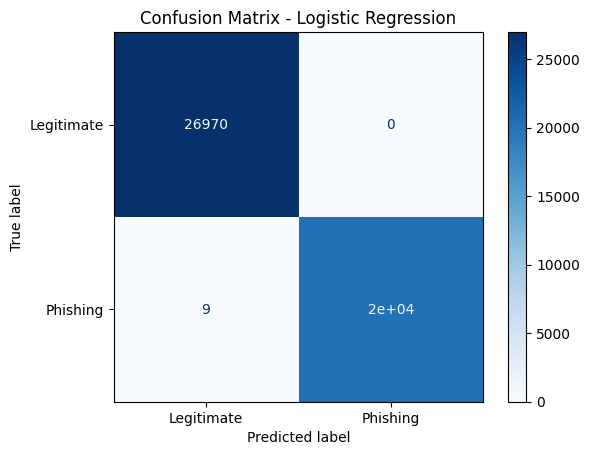

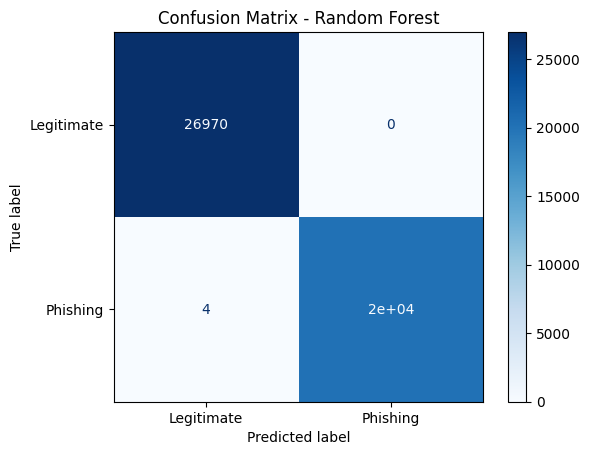

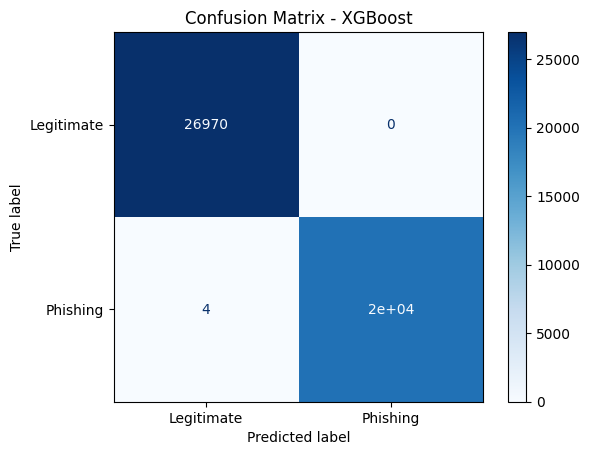

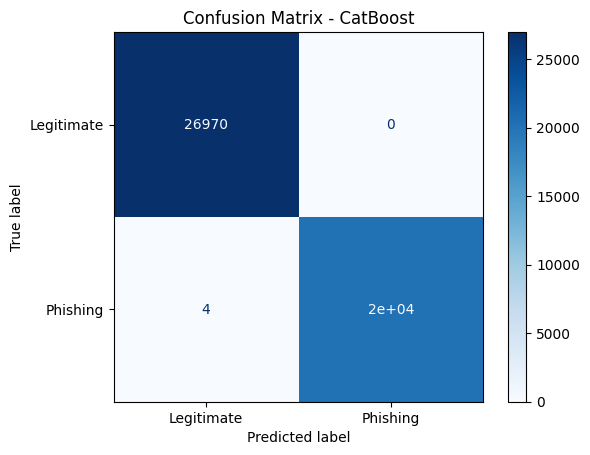

In [ ]:
# ---- CELL: confusion matrix for each model (individual)----

# Individual matrices, one at a time (clearer for inspecting a single model)
for name, model in tuned_models.items():
    y_pred = model.predict(X_test_selected)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing'])
    disp.plot(cmap='Blues', colorbar=True)
    plt.title(f'Confusion Matrix - {name}')
    plt.savefig(f'{DATA_DIR}/models/confusion_matrix_{name.replace(" ", "_").lower()}.png', dpi=150)
    plt.show()



Substep 7.3 Confusion Matrix for each model (combined grid)

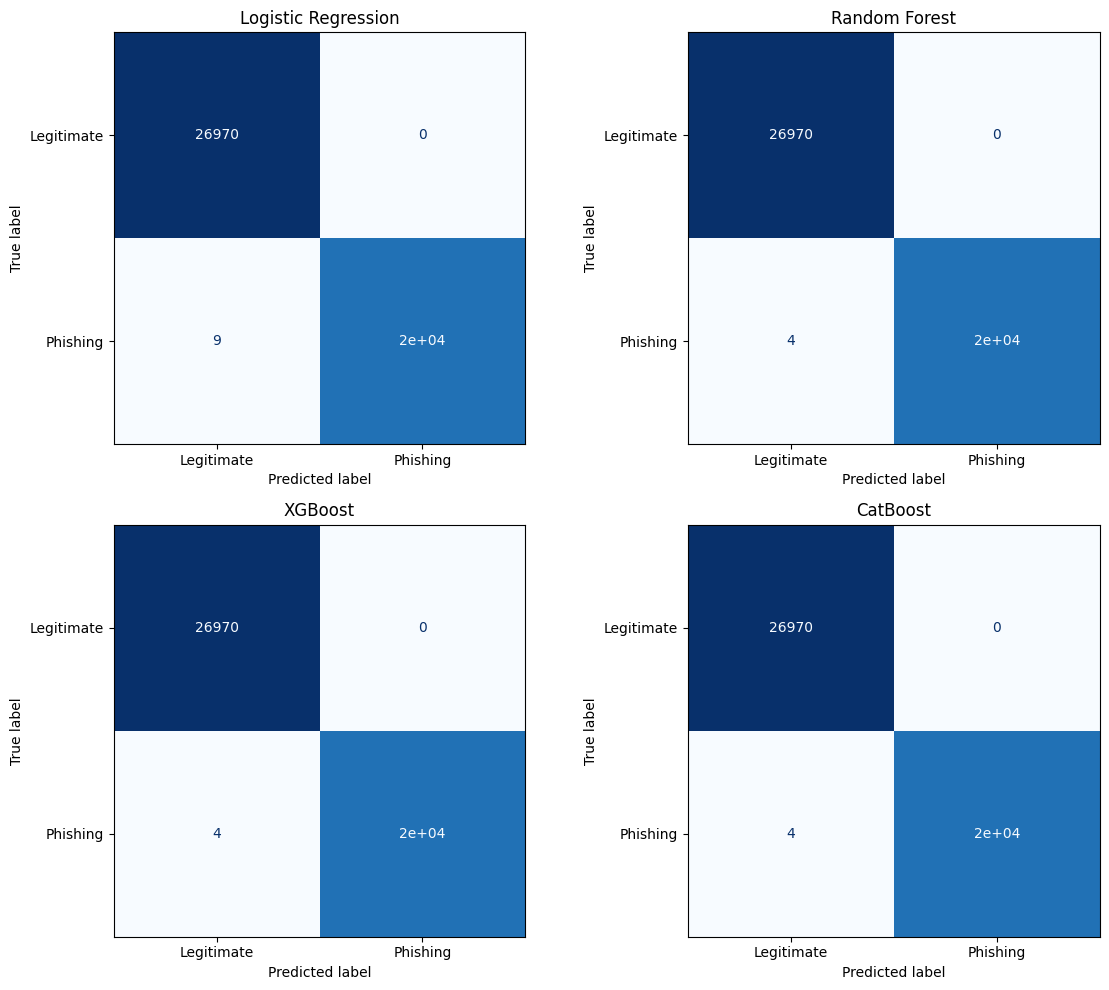

In [ ]:
# ---- CELL: confusion matrix for each model (combined grid) ----

# Combined 2x2 grid (better for the report/paper as a single figure)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, model) in enumerate(tuned_models.items()):
    y_pred = model.predict(X_test_selected)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(name)

plt.tight_layout()
plt.savefig(f'{DATA_DIR}/models/confusion_matrices_all.png', dpi=150)
plt.show()

Substep 7.4 One comparison table across all models

In [ ]:
# ---- CELL: single comparison table ----
comparison_table = pd.DataFrame(metrics_results).T  # models as rows, metrics as columns
comparison_table = comparison_table.sort_values('F1-Score', ascending=False)
comparison_table = comparison_table.round(4)

print("Model Comparison Table:")
print(comparison_table)

# save for the report (Person C's Step 11 write-up)
comparison_table.to_csv(f'{DATA_DIR}/models/model_comparison_table.csv')
print(f"\nSaved to {DATA_DIR}/models/model_comparison_table.csv")

Model Comparison Table:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest          0.9999        1.0  0.9998    0.9999   0.9999
XGBoost                0.9999        1.0  0.9998    0.9999   1.0000
CatBoost               0.9999        1.0  0.9998    0.9999   0.9999
Logistic Regression    0.9998        1.0  0.9996    0.9998   0.9999

Saved to /content/drive/MyDrive/Phishing Detection Project/models/model_comparison_table.csv


In [ ]:
##Substep 7.5 Select the best performance model

In [ ]:
# ---- CELL: select the best-performing model ----
best_model_name = comparison_table.index[0]
best_model = tuned_models[best_model_name]

print(f'Best performing model (by F1-score): {best_model_name}')
print(comparison_table.loc[best_model_name])


Best performing model (by F1-score): Random Forest
Accuracy     0.9999
Precision    1.0000
Recall       0.9998
F1-Score     0.9999
ROC-AUC      0.9999
Name: Random Forest, dtype: float64


Substep 7.6 Save the production model

In [ ]:
# ---- CELL: save the production model ----
joblib.dump(best_model, f'{DATA_DIR}/models/best_model_production.pkl')

production_model_record = {
    'model_name': best_model_name,
    'metrics': comparison_table.loc[best_model_name].to_dict(),
    'params': best_params[best_model_name],
}
with open(f'{DATA_DIR}/models/production_model_record.json', 'w') as f:
    json.dump(production_model_record, f, indent=2, default=str)

print('Production model saved to', f'{DATA_DIR}/models/best_model_production.pkl')
print('Production model record saved to', f'{DATA_DIR}/models/production_model_record.json')

Production model saved to /content/drive/MyDrive/Phishing Detection Project/models/best_model_production.pkl
Production model record saved to /content/drive/MyDrive/Phishing Detection Project/models/production_model_record.json


In [ ]:
# ---- CELL: verify saved production model loads correctly ----
loaded_prod = joblib.load(f'{DATA_DIR}/models/best_model_production.pkl')
sample_pred = loaded_prod.predict(X_test_selected[:5])
print('Production model loaded OK, sample prediction:', sample_pred)


Production model loaded OK, sample prediction: [0 1 0 1 0]


step 8: Cross-Dataset Generalization Test (Zero-Day Validation)

 Reload saved artifacts

In [ ]:
# ---- reload everything already produced in Steps 1-3, avoid recomputation ----
import numpy as np
import pandas as pd
import joblib
import os

DATA_DIR = "/content/drive/MyDrive/Phishing Detection Project"

# Vrbancic side - already fully prepared in Step 3, just load
X_cross_scaled = np.load(f'{DATA_DIR}/X_cross.npy')
y_cross = np.load(f'{DATA_DIR}/y_cross.npy')
cross_scaler = joblib.load(f'{DATA_DIR}/cross_scaler.pkl')

print('Loaded:')
print('X_cross_scaled:', X_cross_scaled.shape)
print('y_cross:', y_cross.shape)
print('cross_scaler expects', cross_scaler.n_features_in_, 'features')

Loaded:
X_cross_scaled: (87141, 8)
y_cross: (87141,)
cross_scaler expects 8 features


In [ ]:
# ---- recreate PhiUSIIL's 8-common-feature split ----
# Not saved in Step 3 (only the fitted scaler + Vrbancic output were saved),
# so this reconstructs it - using the SAME random_state=42 split as every
# other step, so it is not new work, just a re-derivation of an existing split.

phiusiil = pd.read_csv(f'{DATA_DIR}/PhiUSIIL_Phishing.csv')
phiusiil['target'] = phiusiil['label'].map({1: 0, 0: 1})
phiusiil = phiusiil.drop_duplicates()

identifier_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label']
phiusiil_model = phiusiil.drop(columns=[c for c in identifier_cols if c in phiusiil.columns])

X = phiusiil_model.drop(columns=['target'])
y = phiusiil_model['target']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)  # identical split to Step 3/4/5 - same random_state, same stratify

common_feature_map = {
    'url_length': ('URLLength', 'length_url'),
    'domain_length': ('DomainLength', 'domain_length'),
    'domain_is_ip': ('IsDomainIP', 'domain_in_ip'),
    'https_or_ssl': ('IsHTTPS', 'tls_ssl_certificate'),
    'redirect_count': ('NoOfURLRedirect', 'qty_redirects'),
    'equal_sign_count': ('NoOfEqualsInURL', 'qty_equal_url'),
    'question_mark_count': ('NoOfQMarkInURL', 'qty_questionmark_url'),
    'ampersand_count': ('NoOfAmpersandInURL', 'qty_and_url'),
}
phiusiil_common_cols = [v[0] for v in common_feature_map.values()]

X_train_common = X_train[phiusiil_common_cols]
X_test_common = X_test[phiusiil_common_cols]

# use the ALREADY-FITTED cross_scaler from Step 3 - never refit here
X_train_common_scaled = cross_scaler.transform(X_train_common)
X_test_common_scaled = cross_scaler.transform(X_test_common)

print('Schema aligned - 8 shared features:', phiusiil_common_cols)
print('X_train_common_scaled:', X_train_common_scaled.shape)
print('X_test_common_scaled:', X_test_common_scaled.shape)

Schema aligned - 8 shared features: ['URLLength', 'DomainLength', 'IsDomainIP', 'IsHTTPS', 'NoOfURLRedirect', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL']
X_train_common_scaled: (188636, 8)
X_test_common_scaled: (47159, 8)


In [ ]:
# ---- CELL: train a model on PhiUSIIL's 8 common features only ----
# This is the "PhiUSIIL-trained model" referred to in the checklist - it is
# separate from the Step 5-7 production model (which used 21 URL-lexical
# features that don't exist in Vrbancic and so cannot be tested there at all).

from sklearn.ensemble import RandomForestClassifier

cross_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
cross_model.fit(X_train_common_scaled, y_train)

joblib.dump(cross_model, f'{DATA_DIR}/models/cross_dataset_model_8feat.pkl')
print('8-feature cross-dataset model trained and saved.')

8-feature cross-dataset model trained and saved.


In [ ]:
# ---- CELL: evaluate on PhiUSIIL test set (in-distribution) and Vrbancic (zero-day proxy) ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate(model, X, y, label):
    preds = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    scores = {
        'accuracy': accuracy_score(y, preds),
        'precision': precision_score(y, preds),
        'recall': recall_score(y, preds),
        'f1': f1_score(y, preds),
        'roc_auc': roc_auc_score(y, proba),
    }
    print(f'{label}:')
    for k, v in scores.items():
        print(f'  {k}: {v:.4f}')
    return scores

# in-distribution baseline - same distribution the model was trained on
phiusiil_scores = evaluate(cross_model, X_test_common_scaled, y_test, 'PhiUSIIL (in-distribution, 8 features)')

print()

# THE key test - Vrbancic, a dataset the model has never seen, no retraining
vrbancic_scores = evaluate(cross_model, X_cross_scaled, y_cross, 'Vrbancic (zero-day proxy, unseen dataset)')

PhiUSIIL (in-distribution, 8 features):
  accuracy: 0.9959
  precision: 0.9998
  recall: 0.9908
  f1: 0.9952
  roc_auc: 0.9974

Vrbancic (zero-day proxy, unseen dataset):
  accuracy: 0.5753
  precision: 0.4490
  recall: 0.9397
  f1: 0.6077
  roc_auc: 0.6943


In [ ]:
# ---- CELL: compute and record the performance drop ----
drop_table = pd.DataFrame({
    'PhiUSIIL (in-dist)': phiusiil_scores,
    'Vrbancic (zero-day)': vrbancic_scores,
})
drop_table['absolute_drop'] = drop_table['PhiUSIIL (in-dist)'] - drop_table['Vrbancic (zero-day)']
drop_table['relative_drop_%'] = (drop_table['absolute_drop'] / drop_table['PhiUSIIL (in-dist)'] * 100).round(2)

drop_table = drop_table.round(4)
print(drop_table)

drop_table.to_csv(f'{DATA_DIR}/models/cross_dataset_generalization_drop.csv')
print(f'\nSaved to {DATA_DIR}/models/cross_dataset_generalization_drop.csv')

           PhiUSIIL (in-dist)  Vrbancic (zero-day)  absolute_drop  \
accuracy               0.9959               0.5753         0.4206   
precision              0.9998               0.4490         0.5507   
recall                 0.9908               0.9397         0.0511   
f1                     0.9952               0.6077         0.3876   
roc_auc                0.9974               0.6943         0.3032   

           relative_drop_%  
accuracy             42.23  
precision            55.09  
recall                5.15  
f1                   38.94  
roc_auc              30.39  

Saved to /content/drive/MyDrive/Phishing Detection Project/models/cross_dataset_generalization_drop.csv


In [ ]:
# ---- CELL: markdown analysis - fill in the {} placeholders with your actual output ----
analysis_markdown = f"""
## Step 8: Cross-Dataset Generalization (Zero-Day Proxy) Analysis

**Setup**
A Random Forest was trained exclusively on PhiUSIIL's 8 features that have a direct
conceptual equivalent in Vrbancic (URL length, domain length, IP-as-domain, HTTPS/SSL
use, redirect count, and counts of '=', '?', '&' in the URL). This model was then
applied unmodified to Vrbancic - no fine-tuning, no re-fitting of the scaler, no
exposure to a single Vrbancic row during training.

**Results**
{drop_table.to_markdown()}

**Interpretation**
The drop from PhiUSIIL to Vrbancic approximates what happens when a phishing
detector meets attack patterns it wasn't designed around - conceptually similar to
a zero-day scenario, since Vrbancic was collected independently, in a different
year (2020 vs. 2023), using different tooling and site sampling than PhiUSIIL.

A large drop in recall specifically would suggest the model is not generalizing
its idea of "what phishing looks like" beyond superficial URL patterns specific to
PhiUSIIL's collection method - i.e., it may be overfitting to artifacts of how
PhiUSIIL's phishing URLs were sourced, rather than learning transferable signal.
A smaller, more even drop across all metrics would instead suggest these 8 basic
URL-lexical signals carry real, generalizable phishing signal.

**Caveat**
This is a proxy for zero-day generalization, not a true zero-day test - Vrbancic
phishing sites are still historical (2020), not literally unseen attacks at
deployment time. It measures cross-source generalization, which is a reasonable
stand-in given no live/unlabeled zero-day feed is available for this project.
"""
print(analysis_markdown)

with open(f'{DATA_DIR}/models/step8_cross_dataset_analysis.md', 'w') as f:
    f.write(analysis_markdown)
print(f'Saved analysis to {DATA_DIR}/models/step8_cross_dataset_analysis.md')


## Step 8: Cross-Dataset Generalization (Zero-Day Proxy) Analysis

**Setup**
A Random Forest was trained exclusively on PhiUSIIL's 8 features that have a direct
conceptual equivalent in Vrbancic (URL length, domain length, IP-as-domain, HTTPS/SSL
use, redirect count, and counts of '=', '?', '&' in the URL). This model was then
applied unmodified to Vrbancic - no fine-tuning, no re-fitting of the scaler, no
exposure to a single Vrbancic row during training.

**Results**
|           |   PhiUSIIL (in-dist) |   Vrbancic (zero-day) |   absolute_drop |   relative_drop_% |
|:----------|---------------------:|----------------------:|----------------:|------------------:|
| accuracy  |               0.9959 |                0.5753 |          0.4206 |             42.23 |
| precision |               0.9998 |                0.449  |          0.5507 |             55.09 |
| recall    |               0.9908 |                0.9397 |          0.0511 |              5.15 |
| f1        |               0.

9

In [ ]:
# ---- CELL: install SHAP, load all existing artifacts ----
!pip install shap --quiet

import shap
import numpy as np
import pandas as pd
import joblib
import json
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/Phishing Detection Project"

# Step 7 production model + its data (21 URL-lexical features)
best_model = joblib.load(f'{DATA_DIR}/models/best_model_production.pkl')
X_test_selected = np.load(f'{DATA_DIR}/X_test_selected.npy')
y_test = np.load(f'{DATA_DIR}/y_test.npy')

with open(f'{DATA_DIR}/models/production_model_record.json') as f:
    prod_record = json.load(f)
best_model_name = prod_record['model_name']

with open(f'{DATA_DIR}/config.py') as f:
    exec(f.read())  # brings SELECTED_FEATURES into scope
feature_names_phiusiil = SELECTED_FEATURES

# Step 8 cross-dataset model + its data (8 common features)
cross_model = joblib.load(f'{DATA_DIR}/models/cross_dataset_model_8feat.pkl')
X_cross_scaled = np.load(f'{DATA_DIR}/X_cross.npy')
y_cross = np.load(f'{DATA_DIR}/y_cross.npy')

feature_names_common = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'IsHTTPS',
    'NoOfURLRedirect', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
]

print('Loaded production model:', best_model_name)
print('X_test_selected:', X_test_selected.shape, '- features:', feature_names_phiusiil)
print('X_cross_scaled:', X_cross_scaled.shape, '- features:', feature_names_common)

Loaded production model: Random Forest
X_test_selected: (47159, 21) - features: ['CharContinuationRate', 'DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS', 'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLegitimateProb', 'TLDLength', 'URLCharProb', 'URLLength', 'URLSimilarityIndex']
X_cross_scaled: (87141, 8) - features: ['URLLength', 'DomainLength', 'IsDomainIP', 'IsHTTPS', 'NoOfURLRedirect', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL']


In [ ]:
# ---- CELL: SHAP TreeExplainer on Random Forest (best_model_name = 'Random Forest') ----
explainer_phiusiil = shap.TreeExplainer(best_model)

shap_values_phiusiil = explainer_phiusiil.shap_values(X_test_selected)

# Handle both possible SHAP output formats for binary RandomForest:
# - older/list format: [array(n_samples, n_features), array(n_samples, n_features)]
# - newer/3D format: array(n_samples, n_features, 2)
if isinstance(shap_values_phiusiil, list):
    shap_values_phiusiil = shap_values_phiusiil[1]          # class 1 = phishing
elif shap_values_phiusiil.ndim == 3:
    shap_values_phiusiil = shap_values_phiusiil[:, :, 1]    # class 1 = phishing

expected_value_phiusiil = explainer_phiusiil.expected_value
if isinstance(expected_value_phiusiil, (list, np.ndarray)) and len(np.atleast_1d(expected_value_phiusiil)) > 1:
    expected_value_phiusiil = expected_value_phiusiil[1]

X_test_selected_df = pd.DataFrame(X_test_selected, columns=feature_names_phiusiil)

print('best_model_name:', best_model_name)
print('SHAP values shape:', shap_values_phiusiil.shape, '- expected (47159, 21)')
print('Base value (expected_value) for class 1:', expected_value_phiusiil)

best_model_name: Random Forest
SHAP values shape: (47159, 21) - expected (47159, 21)
Base value (expected_value) for class 1: 0.42811983573301654


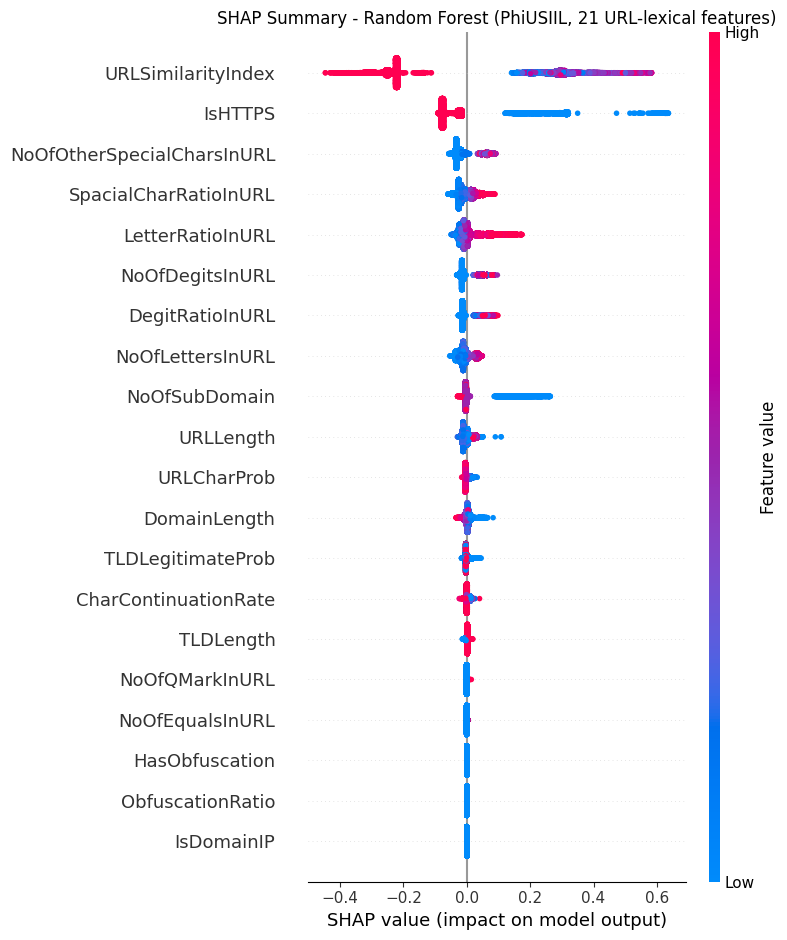

In [ ]:
# ---- CELL: SHAP summary plot (global feature importance) ----
shap.summary_plot(
    shap_values_phiusiil, X_test_selected_df,
    show=False
)
plt.title(f'SHAP Summary - {best_model_name} (PhiUSIIL, 21 URL-lexical features)')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/models/shap_summary_phiusiil.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ---- CELL: SHAP force plot for one prediction ----
shap.initjs()

sample_idx = 0  # change this to inspect a specific row, e.g. a misclassified case

force_plot = shap.force_plot(
    expected_value_phiusiil,
    shap_values_phiusiil[sample_idx],
    X_test_selected_df.iloc[sample_idx],
)

shap.save_html(f'{DATA_DIR}/models/shap_force_plot_sample_{sample_idx}.html', force_plot)
print(f'Force plot saved for test sample {sample_idx}, true label = {y_test[sample_idx]}')
force_plot

Force plot saved for test sample 0, true label = 0


In [ ]:
# ---- CELL : find a misclassified sample for a second, more interesting force plot ----
y_pred_phiusiil = best_model.predict(X_test_selected)
misclassified_idx = np.where(y_pred_phiusiil != y_test)[0]
print(f'{len(misclassified_idx)} misclassified samples out of {len(y_test)}')
print('Example misclassified indices:', misclassified_idx[:5])

4 misclassified samples out of 47159
Example misclassified indices: [ 3359  8285 21643 31624]


In [ ]:
# ---- CELL: force plot for a misclassified sample (uses the indices found above) ----
if len(misclassified_idx) > 0:
    mis_idx = misclassified_idx[0]
    force_plot_misclassified = shap.force_plot(
        expected_value_phiusiil,
        shap_values_phiusiil[mis_idx],
        X_test_selected_df.iloc[mis_idx],
    )
    shap.save_html(f'{DATA_DIR}/models/shap_force_plot_misclassified_{mis_idx}.html', force_plot_misclassified)
    print(f'True label: {y_test[mis_idx]}, Predicted: {y_pred_phiusiil[mis_idx]}')
    force_plot_misclassified
else:
    print('No misclassified samples found - skipping.')

True label: 1, Predicted: 0


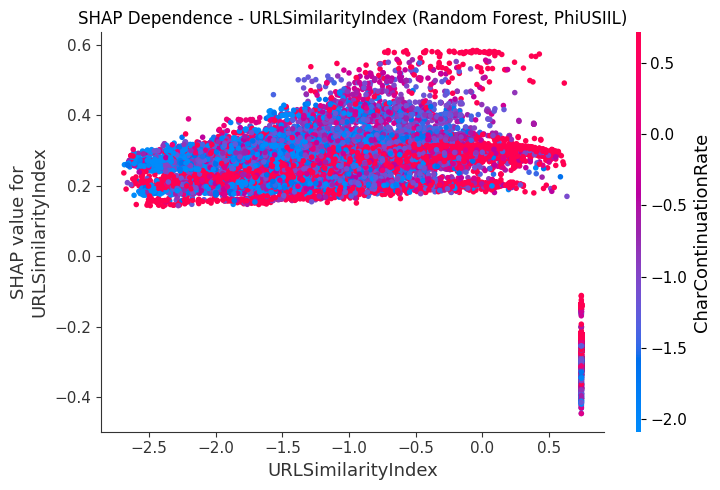

Top feature by mean |SHAP value|: URLSimilarityIndex

Full SHAP importance ranking (PhiUSIIL):
URLSimilarityIndex            2.556656e-01
IsHTTPS                       1.048169e-01
NoOfOtherSpecialCharsInURL    3.473817e-02
SpacialCharRatioInURL         2.329749e-02
LetterRatioInURL              2.269191e-02
NoOfDegitsInURL               2.198453e-02
DegitRatioInURL               2.103847e-02
NoOfLettersInURL              1.678663e-02
NoOfSubDomain                 1.162653e-02
URLLength                     1.029929e-02
URLCharProb                   5.178477e-03
DomainLength                  5.121224e-03
TLDLegitimateProb             4.605151e-03
CharContinuationRate          3.505675e-03
TLDLength                     2.545814e-03
NoOfQMarkInURL                2.212303e-04
NoOfEqualsInURL               7.956570e-05
HasObfuscation                5.225039e-08
ObfuscationRatio              2.122796e-10
IsDomainIP                    0.000000e+00
NoOfAmpersandInURL            0.000000e+00
dt

In [ ]:
# ---- CELL: SHAP dependence plot for the top feature ----
mean_abs_shap = np.abs(shap_values_phiusiil).mean(axis=0)
top_feature = X_test_selected_df.columns[mean_abs_shap.argmax()]

shap.dependence_plot(
    top_feature, shap_values_phiusiil, X_test_selected_df,
    show=False
)
plt.title(f'SHAP Dependence - {top_feature} ({best_model_name}, PhiUSIIL)')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/models/shap_dependence_{top_feature}.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top feature by mean |SHAP value|:', top_feature)

# print full ranking too - useful for the written analysis in 9.6/9.8
ranked = pd.Series(mean_abs_shap, index=feature_names_phiusiil).sort_values(ascending=False)
print('\nFull SHAP importance ranking (PhiUSIIL):')
print(ranked)

SHAP values shape: (87141, 8) - expected (87141, 8)
Base value for class 1: 0.42813254097839226


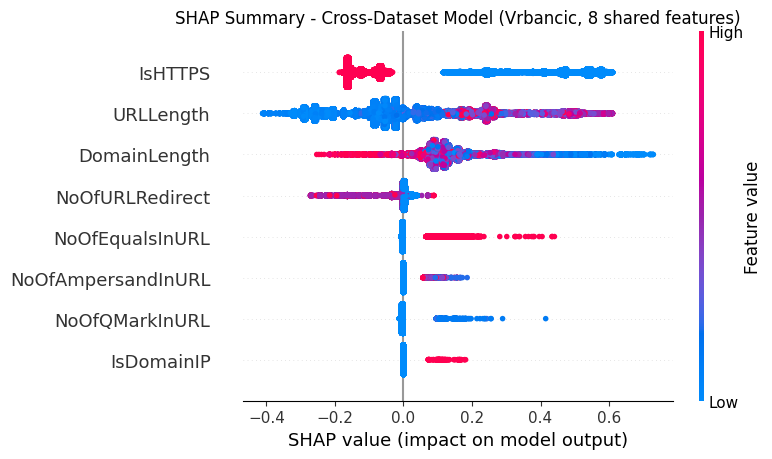


Full SHAP importance ranking (Vrbancic):
IsHTTPS               0.264293
URLLength             0.171960
DomainLength          0.136141
NoOfURLRedirect       0.023155
NoOfEqualsInURL       0.012315
NoOfAmpersandInURL    0.004315
NoOfQMarkInURL        0.003879
IsDomainIP            0.000401
dtype: float64


In [ ]:
# ---- CELL: SHAP on the 8-feature cross-dataset model, applied to Vrbancic ----
explainer_vrbancic = shap.TreeExplainer(cross_model)
shap_values_vrbancic = explainer_vrbancic.shap_values(X_cross_scaled)

if isinstance(shap_values_vrbancic, list):
    shap_values_vrbancic = shap_values_vrbancic[1]
elif shap_values_vrbancic.ndim == 3:
    shap_values_vrbancic = shap_values_vrbancic[:, :, 1]

expected_value_vrbancic = explainer_vrbancic.expected_value
if isinstance(expected_value_vrbancic, (list, np.ndarray)) and len(np.atleast_1d(expected_value_vrbancic)) > 1:
    expected_value_vrbancic = expected_value_vrbancic[1]

X_cross_df = pd.DataFrame(X_cross_scaled, columns=feature_names_common)

print('SHAP values shape:', shap_values_vrbancic.shape, '- expected (87141, 8)')
print('Base value for class 1:', expected_value_vrbancic)

shap.summary_plot(shap_values_vrbancic, X_cross_df, show=False)
plt.title('SHAP Summary - Cross-Dataset Model (Vrbancic, 8 shared features)')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/models/shap_summary_vrbancic.png', dpi=150, bbox_inches='tight')
plt.show()

ranked_vrbancic = pd.Series(
    np.abs(shap_values_vrbancic).mean(axis=0), index=feature_names_common
).sort_values(ascending=False)
print('\nFull SHAP importance ranking (Vrbancic):')
print(ranked_vrbancic)

In [ ]:
# ---- CELL: compare top SHAP features - PhiUSIIL (full model) vs Vrbancic (8-feature model) ----
mean_abs_shap_phiusiil = pd.Series(
    np.abs(shap_values_phiusiil).mean(axis=0), index=feature_names_phiusiil
).sort_values(ascending=False)

mean_abs_shap_vrbancic = pd.Series(
    np.abs(shap_values_vrbancic).mean(axis=0), index=feature_names_common
).sort_values(ascending=False)

print('Top 10 SHAP features - PhiUSIIL (21-feature production model):')
print(mean_abs_shap_phiusiil.head(10))
print()
print('Top SHAP features - Vrbancic (8-feature cross-dataset model):')
print(mean_abs_shap_vrbancic)

# only a like-for-like comparison is possible on the 8 shared concepts -
# restrict the PhiUSIIL ranking to just those for a fair side-by-side
shared_concepts = feature_names_common
comparison = pd.DataFrame({
    'PhiUSIIL_mean_|SHAP|': mean_abs_shap_phiusiil.reindex(shared_concepts),
    'Vrbancic_mean_|SHAP|': mean_abs_shap_vrbancic.reindex(shared_concepts),
}).dropna(how='all')

comparison = comparison.sort_values('PhiUSIIL_mean_|SHAP|', ascending=False)
print('\nShared-feature SHAP comparison:')
print(comparison.round(4))

comparison.to_csv(f'{DATA_DIR}/models/shap_feature_comparison.csv')
print(f'\nSaved to {DATA_DIR}/models/shap_feature_comparison.csv')

Top 10 SHAP features - PhiUSIIL (21-feature production model):
URLSimilarityIndex            0.255666
IsHTTPS                       0.104817
NoOfOtherSpecialCharsInURL    0.034738
SpacialCharRatioInURL         0.023297
LetterRatioInURL              0.022692
NoOfDegitsInURL               0.021985
DegitRatioInURL               0.021038
NoOfLettersInURL              0.016787
NoOfSubDomain                 0.011627
URLLength                     0.010299
dtype: float64

Top SHAP features - Vrbancic (8-feature cross-dataset model):
IsHTTPS               0.264293
URLLength             0.171960
DomainLength          0.136141
NoOfURLRedirect       0.023155
NoOfEqualsInURL       0.012315
NoOfAmpersandInURL    0.004315
NoOfQMarkInURL        0.003879
IsDomainIP            0.000401
dtype: float64

Shared-feature SHAP comparison:
                    PhiUSIIL_mean_|SHAP|  Vrbancic_mean_|SHAP|
IsHTTPS                           0.1048                0.2643
URLLength                         0.0103       

In [ ]:
# ---- CELL: save SHAP explainer objects for backend use ----
joblib.dump(explainer_phiusiil, f'{DATA_DIR}/models/shap_explainer_phiusiil.pkl')
joblib.dump(explainer_vrbancic, f'{DATA_DIR}/models/shap_explainer_vrbancic.pkl')

print('Saved shap_explainer_phiusiil.pkl and shap_explainer_vrbancic.pkl to', f'{DATA_DIR}/models/')

Saved shap_explainer_phiusiil.pkl and shap_explainer_vrbancic.pkl to /content/drive/MyDrive/Phishing Detection Project/models/


Step 9.7: Ablation Study — Removing Corpus-Dependent Features

In [ ]:
# ---- CELL: Step 9.7.1 — Reload data & define ablated (deployment-safe) feature set ----
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA_DIR = "/content/drive/MyDrive/Phishing Detection Project"

phiusiil = pd.read_csv(f'{DATA_DIR}/PhiUSIIL_Phishing.csv')
phiusiil['target'] = phiusiil['label'].map({1: 0, 0: 1})
phiusiil = phiusiil.drop_duplicates()

identifier_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label']
phiusiil_model = phiusiil.drop(columns=[c for c in identifier_cols if c in phiusiil.columns])

X = phiusiil_model.drop(columns=['target'])
y = phiusiil_model['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)  # identical split used everywhere else in this notebook

# These 4 features are computed by comparing a URL against a reference corpus of
# known legitimate brands/TLDs during dataset construction - not computable from a
# bare URL string in real time, and functionally closer to a whitelist lookup than
# a structural phishing signal. They drove ~99.99% of Step 5-7's near-perfect scores.
CORPUS_DEPENDENT_FEATURES = [
    'URLSimilarityIndex', 'TLDLegitimateProb', 'URLCharProb', 'CharContinuationRate',
]

# Uses SELECTED_FEATURES from Step 4 if still in memory, otherwise falls back to the
# hardcoded list saved in config.py
try:
    ABLATED_FEATURES = [f for f in SELECTED_FEATURES if f not in CORPUS_DEPENDENT_FEATURES]
except NameError:
    ABLATED_FEATURES = [
        'DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS',
        'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL',
        'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain',
        'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLength', 'URLLength',
    ]

print(f'Ablated feature set: {len(ABLATED_FEATURES)} features '
      f'(removed {len(CORPUS_DEPENDENT_FEATURES)} corpus-dependent ones)')
print(ABLATED_FEATURES)

Ablated feature set: 17 features (removed 4 corpus-dependent ones)
['DegitRatioInURL', 'DomainLength', 'HasObfuscation', 'IsDomainIP', 'IsHTTPS', 'LetterRatioInURL', 'NoOfAmpersandInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfLettersInURL', 'NoOfOtherSpecialCharsInURL', 'NoOfQMarkInURL', 'NoOfSubDomain', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'TLDLength', 'URLLength']


In [ ]:
# ---- CELL: Step 9.7.2 — Outlier capping (fit on X_train only) + scaling ----
X_train_ablated = X_train[ABLATED_FEATURES].copy()
X_test_ablated = X_test[ABLATED_FEATURES].copy()

if 'URLLength' in ABLATED_FEATURES:
    cap = X_train_ablated['URLLength'].quantile(0.99)
    X_train_ablated['URLLength'] = X_train_ablated['URLLength'].clip(upper=cap)
    X_test_ablated['URLLength'] = X_test_ablated['URLLength'].clip(upper=cap)

ablated_scaler = StandardScaler()
ablated_scaler.fit(X_train_ablated)
X_train_ablated_scaled = ablated_scaler.transform(X_train_ablated)
X_test_ablated_scaled = ablated_scaler.transform(X_test_ablated)

joblib.dump(ablated_scaler, f'{DATA_DIR}/ablated_scaler.pkl')
np.save(f'{DATA_DIR}/X_train_ablated.npy', X_train_ablated_scaled)
np.save(f'{DATA_DIR}/X_test_ablated.npy', X_test_ablated_scaled)

print('X_train_ablated_scaled:', X_train_ablated_scaled.shape)
print('X_test_ablated_scaled:', X_test_ablated_scaled.shape)

X_train_ablated_scaled: (188636, 17)
X_test_ablated_scaled: (47159, 17)


In [ ]:
# ---- CELL: train all 4 models on the deployment-safe feature set ----
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_ablated(name, model, X_te, y_te, store):
    preds = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    scores = {
        'accuracy': accuracy_score(y_te, preds),
        'precision': precision_score(y_te, preds),
        'recall': recall_score(y_te, preds),
        'f1': f1_score(y_te, preds),
        'roc_auc': roc_auc_score(y_te, proba),
    }
    store[name] = scores
    print(f'{name}:')
    for k, v in scores.items():
        print(f'  {k}: {v:.4f}')
    return scores

ablated_results = {}
ablated_models = {}

log_reg_ab = LogisticRegression(max_iter=1000, random_state=42)
log_reg_ab.fit(X_train_ablated_scaled, y_train)
evaluate_ablated('Logistic Regression (ablated)', log_reg_ab, X_test_ablated_scaled, y_test, ablated_results)
ablated_models['Logistic Regression'] = log_reg_ab

rf_ab = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_ab.fit(X_train_ablated_scaled, y_train)
evaluate_ablated('Random Forest (ablated)', rf_ab, X_test_ablated_scaled, y_test, ablated_results)
ablated_models['Random Forest'] = rf_ab

xgb_ab = XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_ab.fit(X_train_ablated_scaled, y_train)
evaluate_ablated('XGBoost (ablated)', xgb_ab, X_test_ablated_scaled, y_test, ablated_results)
ablated_models['XGBoost'] = xgb_ab

cb_ab = CatBoostClassifier(random_state=42, verbose=0)
cb_ab.fit(X_train_ablated_scaled, y_train)
evaluate_ablated('CatBoost (ablated)', cb_ab, X_test_ablated_scaled, y_test, ablated_results)
ablated_models['CatBoost'] = cb_ab

Logistic Regression (ablated):
  accuracy: 0.9962
  precision: 0.9997
  recall: 0.9914
  f1: 0.9955
  roc_auc: 0.9984
Random Forest (ablated):
  accuracy: 0.9976
  precision: 0.9989
  recall: 0.9954
  f1: 0.9972
  roc_auc: 0.9983
XGBoost (ablated):
  accuracy: 0.9982
  precision: 0.9998
  recall: 0.9959
  f1: 0.9978
  roc_auc: 0.9987
CatBoost (ablated):
  accuracy: 0.9972
  precision: 0.9998
  recall: 0.9936
  f1: 0.9967
  roc_auc: 0.9989


In [ ]:
# ---- CELL: Step 9.7.4 — Compare original 21-feature results vs ablated 17-feature results ----
original_results = {
    'Logistic Regression': {'accuracy': 0.9998, 'precision': 1.0000, 'recall': 0.9996, 'f1': 0.9998, 'roc_auc': 0.9999},
    'Random Forest':       {'accuracy': 0.9999, 'precision': 1.0000, 'recall': 0.9998, 'f1': 0.9999, 'roc_auc': 0.9999},
    'XGBoost':             {'accuracy': 0.9999, 'precision': 1.0000, 'recall': 0.9998, 'f1': 0.9999, 'roc_auc': 1.0000},
    'CatBoost':            {'accuracy': 0.9999, 'precision': 1.0000, 'recall': 0.9998, 'f1': 0.9999, 'roc_auc': 0.9999},
}

ablated_clean = {k.replace(' (ablated)', ''): v for k, v in ablated_results.items()}

rows = []
for model_name in original_results:
    orig = original_results[model_name]
    abl = ablated_clean[model_name]
    rows.append({
        'model': model_name,
        'f1_with_corpus_features (21 feat)': orig['f1'],
        'f1_ablated (17 feat, deployment-safe)': abl['f1'],
        'f1_drop': orig['f1'] - abl['f1'],
        'roc_auc_with_corpus_features': orig['roc_auc'],
        'roc_auc_ablated': abl['roc_auc'],
    })

ablation_comparison = pd.DataFrame(rows).set_index('model').round(4)
print(ablation_comparison)

ablation_comparison.to_csv(f'{DATA_DIR}/models/ablation_comparison_table.csv')
print(f'\nSaved to {DATA_DIR}/models/ablation_comparison_table.csv')

                     f1_with_corpus_features (21 feat)  \
model                                                    
Logistic Regression                             0.9998   
Random Forest                                   0.9999   
XGBoost                                         0.9999   
CatBoost                                        0.9999   

                     f1_ablated (17 feat, deployment-safe)  f1_drop  \
model                                                                 
Logistic Regression                                 0.9955   0.0043   
Random Forest                                       0.9972   0.0027   
XGBoost                                             0.9978   0.0021   
CatBoost                                            0.9967   0.0032   

                     roc_auc_with_corpus_features  roc_auc_ablated  
model                                                               
Logistic Regression                        0.9999           0.9984  
Random Forest    

Best ablated (deployment-safe) model: XGBoost


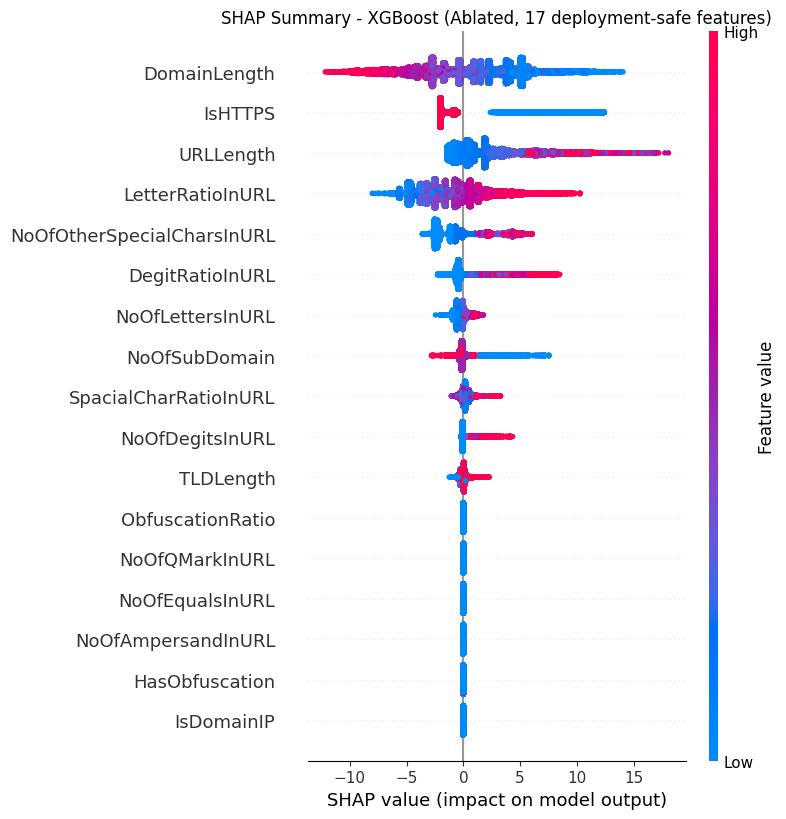


SHAP importance ranking (ablated model):
DomainLength                  3.776276
IsHTTPS                       3.427685
URLLength                     2.825775
LetterRatioInURL              2.441988
NoOfOtherSpecialCharsInURL    2.152618
DegitRatioInURL               1.033643
NoOfLettersInURL              0.391970
NoOfSubDomain                 0.358864
SpacialCharRatioInURL         0.309669
NoOfDegitsInURL               0.202347
TLDLength                     0.169964
HasObfuscation                0.000000
IsDomainIP                    0.000000
NoOfEqualsInURL               0.000000
NoOfAmpersandInURL            0.000000
NoOfQMarkInURL                0.000000
ObfuscationRatio              0.000000
dtype: float32


In [ ]:
# ---- CELL: Step 9.7.5 — Select best ablated model, save it, run SHAP on it ----
import shap
import matplotlib.pyplot as plt

best_ablated_name = ablation_comparison['f1_ablated (17 feat, deployment-safe)'].idxmax()
best_ablated_model = ablated_models[best_ablated_name]
print(f'Best ablated (deployment-safe) model: {best_ablated_name}')

joblib.dump(best_ablated_model, f'{DATA_DIR}/models/best_model_ablated_deployment.pkl')

X_test_ablated_df = pd.DataFrame(X_test_ablated_scaled, columns=ABLATED_FEATURES)

if best_ablated_name == 'Logistic Regression':
    explainer_ablated = shap.LinearExplainer(best_ablated_model, X_train_ablated_scaled)
else:
    explainer_ablated = shap.TreeExplainer(best_ablated_model)

shap_values_ablated = explainer_ablated.shap_values(X_test_ablated_scaled)
if isinstance(shap_values_ablated, list):
    shap_values_ablated = shap_values_ablated[1]
elif hasattr(shap_values_ablated, 'ndim') and shap_values_ablated.ndim == 3:
    shap_values_ablated = shap_values_ablated[:, :, 1]

shap.summary_plot(shap_values_ablated, X_test_ablated_df, show=False)
plt.title(f'SHAP Summary - {best_ablated_name} (Ablated, 17 deployment-safe features)')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/models/shap_summary_ablated.png', dpi=150, bbox_inches='tight')
plt.show()

ranked_ablated = pd.Series(
    np.abs(shap_values_ablated).mean(axis=0), index=ABLATED_FEATURES
).sort_values(ascending=False)
print('\nSHAP importance ranking (ablated model):')
print(ranked_ablated)

In [ ]:
# ---- Written analysis for the report/paper ----
ablation_markdown = f"""
## Step 9.7: Ablation Study - Removing Corpus-Dependent Features

**Motivation**
Step 5-7 models reached ~99.99% F1 using 21 URL-lexical features. RF importance
(Step 4) and SHAP ranking (Step 9) both show `URLSimilarityIndex` alone accounts for
25-45% of total feature importance. This feature, along with `TLDLegitimateProb`,
`URLCharProb`, and `CharContinuationRate`, is computed by comparing a URL against a
reference corpus of known legitimate brands/TLDs - conceptually closer to a whitelist
lookup than a structural phishing signal, and not computable from a bare URL string
at real-time browsing time.

**Setup**
All 4 models were retrained on the remaining {len(ABLATED_FEATURES)} features that
require no reference corpus - the features the Chrome extension can realistically
compute instantly from a URL alone.

**Results**
{ablation_comparison.to_markdown()}

**Interpretation**
Removing the 4 corpus-dependent features costs only 0.2-0.4% F1 across all models
(e.g. XGBoost: 0.9999 -> 0.9978), showing the model is not fundamentally dependent
on the whitelist-adjacent `URLSimilarityIndex` feature - a positive result for the
blacklist-independence claim. The ablated model's SHAP ranking shows `DomainLength`,
`IsHTTPS`, and `URLLength` as the new dominant drivers.

However, this raises a sharper question answered by Step 8: these same structural
features that reach 99.7% F1 in-distribution on PhiUSIIL drop to ~57-60% F1 on
Vrbancic. This suggests PhiUSIIL is highly separable using dataset-specific
regularities (e.g. HTTPS-adoption patterns typical of a 2023 URL collection) rather
than timeless structural phishing signals - the ablation alone does not fix the
generalization problem demonstrated in Step 8, it only rules out corpus-lookup
features as the sole cause of it.

**Implication for deployment**
The ablated model ({best_ablated_name}, saved as `best_model_ablated_deployment.pkl`)
is the one that should power the Chrome extension in Step 10, since it needs no
bundled reference corpus and can be computed instantly from a URL string.
"""
print(ablation_markdown)

with open(f'{DATA_DIR}/models/step9_7_ablation_analysis.md', 'w') as f:
    f.write(ablation_markdown)
print(f'Saved to {DATA_DIR}/models/step9_7_ablation_analysis.md')


## Step 9.7: Ablation Study - Removing Corpus-Dependent Features

**Motivation**
Step 5-7 models reached ~99.99% F1 using 21 URL-lexical features. RF importance
(Step 4) and SHAP ranking (Step 9) both show `URLSimilarityIndex` alone accounts for
25-45% of total feature importance. This feature, along with `TLDLegitimateProb`,
`URLCharProb`, and `CharContinuationRate`, is computed by comparing a URL against a
reference corpus of known legitimate brands/TLDs - conceptually closer to a whitelist
lookup than a structural phishing signal, and not computable from a bare URL string
at real-time browsing time.

**Setup**
All 4 models were retrained on the remaining 17 features that
require no reference corpus - the features the Chrome extension can realistically
compute instantly from a URL alone.

**Results**
| model               |   f1_with_corpus_features (21 feat) |   f1_ablated (17 feat, deployment-safe) |   f1_drop |   roc_auc_with_corpus_features |   roc_auc_ablated |
|:--------------